# EDA na Prática

Nas aulas 9 e 10 vimos os quatro princípios da EDA (estrutural, distribucional, relacional e detecção de outliers/anomalias), como tratar dados ausentes e outliers, e como fazer análise descritiva, bivariada e multivariada. Hoje é a hora de **aplicarmos na prática**. Durante a primeira hora da aula, serão apresentadas as técnicas no dataset *Heart Disease* (UCI) e depois **cada aluno** irá aplicar as técnicas no dataset que foi escolhido semana passada.

*Relembrando*: a EDA não é uma linha reta

A EDA costuma ser apresentada como uma sequência de etapas (estrutura → tratamento → descrição → relação), mas na prática ela é **iterativa**: às vezes tratamos um outlier, olhamos a estatística descritiva de novo, e percebemos que precisa voltar atrás. Hoje vamos deixar isso explícito: olhamos a estatística descritiva **antes** de tratar dados ausentes/outliers (pra saber *como* tratar) e **depois** (pra confirmar o efeito do tratamento).

## Como funcionará a atividade

- **Duração:** ~1h40min
- **Formato:** individual
- **Passo 1:** acompanhem a demonstração no dataset Heart Disease.
- **Passo 2:** importem o dataset que vocês escolheram e enviaram anteriormente.
- **Passo 3:** repliquem o mesmo ciclo no dataset escolhido, respondendo às perguntas guiadas.
- **Uso de IA:** permitido, conforme o Plano de Ensino — documentem na seção final.

## Setup de Bibliotecas e Dados

##para baixar


In [ ]:
# Instalação da biblioteca oficial do Kaggle
!pip install kagglehub --quiet

import kagglehub
import os

# Download do dataset diretamente do Kaggle
dataset_path = kagglehub.dataset_download(
    "debayank2024/fifa-2026-player-performance"
)

# Localizando o arquivo CSV
arquivos_csv = [
    arquivo
    for arquivo in os.listdir(dataset_path)
    if arquivo.endswith(".csv")
]

print("Arquivos CSV encontrados:", arquivos_csv)

# Carregando o dataset
arquivo_csv = os.path.join(dataset_path, arquivos_csv[0])
df = pd.read_csv(arquivo_csv)

df.head()

Using Colab cache for faster access to the 'fifa-2026-player-performance' dataset.
Arquivos CSV encontrados: ['fifa2026_player_performance_clean.csv']


,player_name,nationality,club,position,age,market_value_eur_m,season,competition,match_id,minutes_played,...,assists,shots_on_target,pass_accuracy_pct,tackles,distance_covered_km,match_rating,yellow_card,red_card,fouls_committed,injured_flag
0,Achraf Hakimi,Morocco,Paris Saint-Germain,RB,21,11.01,2025/26,Champions League,111378,53,...,0,0,NaN,2,5.79,5.8,False,False,0,False
1,Achraf Hakimi,Morocco,Paris Saint-Germain,RB,21,10.69,2025/26,Champions League,111379,63,...,0,0,85.2,2,10.31,6.9,False,False,3,False
2,Achraf Hakimi,Morocco,Paris Saint-Germain,RB,21,10.61,2025/26,Champions League,111380,90,...,0,0,94.8,4,14.50,7.5,False,False,0,False
3,Achraf Hakimi,Morocco,Paris Saint-Germain,RB,21,11.26,2025/26,Champions League,111381,12,...,0,0,74.9,1,0.91,4.0,False,False,3,False
4,Achraf Hakimi,Morocco,Paris Saint-Germain,RB,21,10.50,2025/26,Champions League,111382,39,...,0,0,78.0,3,4.36,5.0,False,False,2,False


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"
COR_CONTEXTO = "#e9d4d0"
COR_DESTAQUE = "#2d223a"
COR_ALERTA = "tab:red"

## Carregando o Dataset

In [ ]:
df = pd.read_csv("fifa2026_player_performance_clean.csv")

df.head()

,player_name,nationality,club,position,age,market_value_eur_m,season,competition,match_id,minutes_played,...,assists,shots_on_target,pass_accuracy_pct,tackles,distance_covered_km,match_rating,yellow_card,red_card,fouls_committed,injured_flag
0,Achraf Hakimi,Morocco,Paris Saint-Germain,RB,21,11.01,2025/26,Champions League,111378,53,...,0,0,NaN,2,5.79,5.8,False,False,0,False
1,Achraf Hakimi,Morocco,Paris Saint-Germain,RB,21,10.69,2025/26,Champions League,111379,63,...,0,0,85.2,2,10.31,6.9,False,False,3,False
2,Achraf Hakimi,Morocco,Paris Saint-Germain,RB,21,10.61,2025/26,Champions League,111380,90,...,0,0,94.8,4,14.50,7.5,False,False,0,False
3,Achraf Hakimi,Morocco,Paris Saint-Germain,RB,21,11.26,2025/26,Champions League,111381,12,...,0,0,74.9,1,0.91,4.0,False,False,3,False
4,Achraf Hakimi,Morocco,Paris Saint-Germain,RB,21,10.50,2025/26,Champions League,111382,39,...,0,0,78.0,3,4.36,5.0,False,False,2,False


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

## 1. Princípio Estrutural

Antes de analisar os dados, é necessário entender a estrutura do dataset escolhido. O conjunto FIFA 2026 Player Performance contém informações sobre jogadores e seus desempenhos, incluindo características como idade, posição, clube e diversas métricas registradas nas observações. Ele analisa participações individuas dos jogadores na copa de 26, ou seja, apesar de 13k de linhas não temos 13 mil jogadores.
OBS: Maira, depois que eu escolhi o dataset e fui fazendo a atividade, notei que alguns dados estão falsos. notei isso logo após rodar o comando df.describe e perceber que a idade máxima era 39, sendo que Cristiano Ronaldo tem 41 e jogou a copa. não só a idade, mas alguns gols também estão perdidos, isso sugere que existem informações simuladas. Dito isso, manterei os valores iguais no dataset.

### Dimensão e Tipos de Dados

In [ ]:
df.shape

(303, 14)

O dataset possui 13.397 registros e 21 colunas

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13397 entries, 0 to 13396
Data columns (total 21 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   player_name          13397 non-null  object 
 1   nationality          13397 non-null  object 
 2   club                 13397 non-null  object 
 3   position             13397 non-null  object 
 4   age                  13397 non-null  int64  
 5   market_value_eur_m   13127 non-null  float64
 6   season               13397 non-null  object 
 7   competition          13397 non-null  object 
 8   match_id             13397 non-null  int64  
 9   minutes_played       13397 non-null  int64  
 10  goals                13397 non-null  int64  
 11  assists              13397 non-null  int64  
 12  shots_on_target      13397 non-null  int64  
 13  pass_accuracy_pct    12590 non-null  float64
 14  tackles              13397 non-null  int64  
 15  distance_covered_km  12718 non-null 

O dataset tem muitos tipos de variáveis. O que é interessante observar é como esses tipos de variáveis se encaixam em jogadores, por exemplo, injured_flag é booleano pois ele não busca sinalizar a quantidade de lesões, e sim se ocorreu ou não.

In [ ]:
df.describe()

,age,market_value_eur_m,match_id,minutes_played,goals,assists,shots_on_target,pass_accuracy_pct,tackles,distance_covered_km,match_rating,fouls_committed
count,13397.000000,13127.000000,13397.000000,13397.000000,13397.000000,13397.000000,13397.000000,12590.000000,13397.000000,12718.000000,13397.000000,13397.000000
mean,28.273569,22.698472,106698.000000,59.996716,0.164813,0.127566,0.292006,75.107911,0.980817,6.489581,6.121983,1.297529
std,6.435837,28.500436,3867.525113,27.647981,0.440731,0.369907,0.621698,14.319883,1.363312,3.709890,1.231560,1.144203
min,17.000000,0.570000,100000.000000,1.000000,0.000000,0.000000,0.000000,30.000000,0.000000,0.190000,3.000000,0.000000
25%,23.000000,5.870000,103349.000000,38.000000,0.000000,0.000000,0.000000,66.100000,0.000000,3.560000,5.200000,0.000000
50%,28.000000,12.570000,106698.000000,67.000000,0.000000,0.000000,0.000000,77.300000,0.000000,6.310000,6.200000,1.000000
75%,34.000000,27.935000,110047.000000,86.000000,0.000000,0.000000,0.000000,86.300000,1.000000,9.030000,7.000000,2.000000
max,39.000000,220.870000,113396.000000,90.000000,4.000000,3.000000,6.000000,99.800000,10.000000,14.500000,10.000000,9.000000


### Duplicadas

In [ ]:
df.duplicated().sum()

np.int64(0)

peguei um dataset do kaggle que estava Clean (sem duplicadas).


## 2. Dados Faltantes

In [ ]:
df.isna().sum()

,0
player_name,0.00
nationality,0.00
club,0.00
position,0.00
age,0.00
market_value_eur_m,2.02
season,0.00
competition,0.00
match_id,0.00
minutes_played,0.00


**Discussao:** Alguma feature tem dados ausentes nos seus dados?

*Resposta*: Sim, 3 para ser mais exato. market_value_eur_m = 270; pass_accuracu_pct=807; distance_convered_km= 679

#### Identificando o mecanismo de dados ausentes

Encontrei ausências em três variáveis: valor de mercado, precisão de passes e distância percorrida. o dataset apresenta possíveis limitações de qualidade e não fornece informações detalhadas sobre o processo de coleta de cada observação, não é possível determinar o mecanismo de ausência apenas pelo conhecimento de domínio.

**As ausencias ocorrem juntas?**

Contar ausentes por coluna não conta a história toda: se duas colunas ficam ausentes **nas mesmas linhas**, isso é um indício de padrão sistemático (ex: um exame que não foi feito, afetando várias medidas de uma vez).



In [ ]:
cols_com_ausentes = df.columns[df.isna().any()].tolist()
print("Colunas com ausentes:", cols_com_ausentes)
print(df[cols_com_ausentes].isna().sum())


Colunas com ausentes: ['market_value_eur_m', 'pass_accuracy_pct', 'distance_covered_km']
market_value_eur_m     270
pass_accuracy_pct      807
distance_covered_km    679
dtype: int64


In [ ]:
padroes_ausencia = (
    df[cols_com_ausentes]
    .isna()
    .value_counts()
)

padroes_ausencia

market_value_eur_m  pass_accuracy_pct  distance_covered_km
False               False              False                  11707
                    True               False                    753
                    False              True                     628
True                False              False                    243
False               True               True                      39
True                True               False                     15
                    False              True                      12
Name: count, dtype: int64

A análise dos padrões de ausência mostra que a maior parte dos valores faltantes ocorre de forma isolada. Apenas 15 registros apresentam simultaneamente ausência em market_value_eur_m e pass_accuracy_pct, 12 em market_value_eur_m e distance_covered_km, e 39 em pass_accuracy_pct e distance_covered_km. Nenhum registro apresenta ausência nas três variáveis ao mesmo tempo. Portanto, não há evidência visual de um forte padrão conjunto de ausência entre as três variáveis.

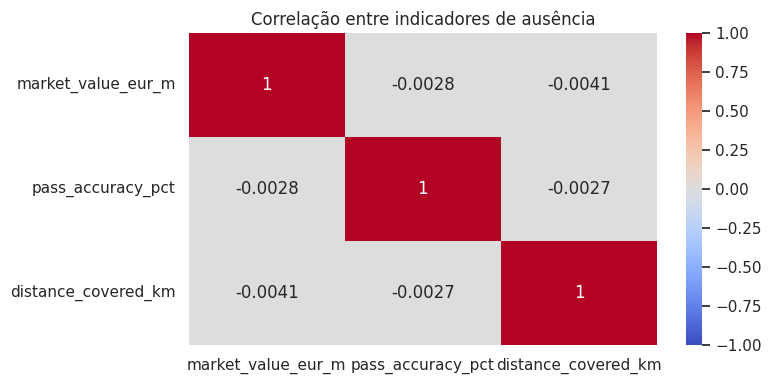

In [ ]:
ausencias = df[cols_com_ausentes].isna()

plt.figure(figsize=(8, 4))
sns.heatmap(
    ausencias.corr(),
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlação entre indicadores de ausência")
plt.tight_layout()
plt.show()

**Pra discutir:** quantas linhas têm as duas colunas ausentes ao mesmo tempo? Isso muda a hipótese sobre o mecanismo de ausência (MCAR/MAR/MNAR), ou parecem eventos independentes?

*Relembrando:*
- MCAR: Mecanismo Aleatório e sem viés
- MAR: Mecanismo Randômico e com viés possível de corrigir
- MNAR: Mecanismo Não Randômico relacionada a própria feature

- *Se supormos que a ausência depende do próprio valor que está faltando*: por exemplo, o paciente não fez o exame porque já se suspeitava (por sinais clínicos observados previamente) que o resultado seria anormal, e o exame extra não seria necessário, isso seria classificado como **MNAR**.
- *Se supormos que a ausência depende de algo externo ao valor em si*: por exemplo, o protocolo de coleta decidiu não solicitar aquele exame, ou o custo do procedimento limitou a coleta, independente do que o resultado provavelmente seria — isso seria classificado como **MAR** (ou até **MCAR**, se a decisão for arbitrária e não sistemática).

Com as informações disponíveis, não é possível classificar definitivamente o mecanismo como MCAR, MAR ou MNAR. O baixo número de ausências simultâneas sugere que as três variáveis não apresentam um forte mecanismo conjunto de ausência. Entretanto, ainda é necessário verificar se as ausências estão associadas a outras variáveis observáveis do dataset.

**Nota para quando vocês replicarem no dataset de vocês:** se o dataset escolhido tiver *muitas* colunas com *muitos* ausentes, aí sim uma correlação (ou um heatmap) entre os indicadores de ausência passa a fazer sentido. O problema neste caso foi o volume pequeno, não a técnica em si.

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar ausentes ou outliers), vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai *orientar as decisões de tratamento* na próxima seção. Por exemplo, se uma variável for muito assimétrica, faz mais sentido imputar com a mediana do que com a média.

In [ ]:
VARS_QUANT = [
    "age",
    "market_value_eur_m",
    "minutes_played",
    "goals",
    "assists",
    "shots_on_target",
    "pass_accuracy_pct",
    "tackles",
    "distance_covered_km",
    "match_rating",
    "fouls_committed"
]

VARS_QUALI = [
    "nationality",
    "club",
    "position",
    "season",
    "competition",
    "yellow_card",
    "red_card",
    "injured_flag"
]

### Tabela descritiva, com assimetria e curtose

desc = df[VARS_QUANT].describe().T

desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
)

,mean,median,std,min,max,skewness,kurtosis
age,28.27,28.00,6.44,17.00,39.00,0.01,-1.17
market_value_eur_m,22.70,12.57,28.50,0.57,220.87,2.84,10.55
minutes_played,60.00,67.00,27.65,1.00,90.00,-0.61,-0.92
goals,0.16,0.00,0.44,0.00,4.00,3.02,10.58
assists,0.13,0.00,0.37,0.00,3.00,3.06,10.13
shots_on_target,0.29,0.00,0.62,0.00,6.00,2.55,7.83
pass_accuracy_pct,75.11,77.30,14.32,30.00,99.80,-0.67,-0.02
tackles,0.98,0.00,1.36,0.00,10.00,1.76,3.33
distance_covered_km,6.49,6.31,3.71,0.19,14.50,0.29,-0.68
match_rating,6.12,6.20,1.23,3.00,10.00,-0.03,-0.51


**Pra discutir:** olhando a tabela, quais variáveis já parecem assimétricas (`skewness` acima de 1) ou com cauda pesada (`kurtosis` maior que 2 em módulo)?

Isso é coerente com o que vocês esperariam fisiologicamente (ex: colesterol e pressão em repouso costumam ter poucos pacientes com valores muito altos, puxando a cauda direita)?

**RESPOSTA**
Sim, as com skewness acima de 1 são realmente esperadas para um dataset de futebol, alguns jogadores costumam ter preços, ou outras variáveis, que podem puxar a assimetria. Eles também indicam caudas mais 'pesadas' por causas dos valores extremos. Outras variáveis como idade tem mais simetria.

### Distribuições de dados

Onde fizer sentido, comparamos "Sem doença" (rosa) vs. "Com doença" (roxo). Vamos utilizar esta convenção de cor que vamos manter até a análise bivariada.


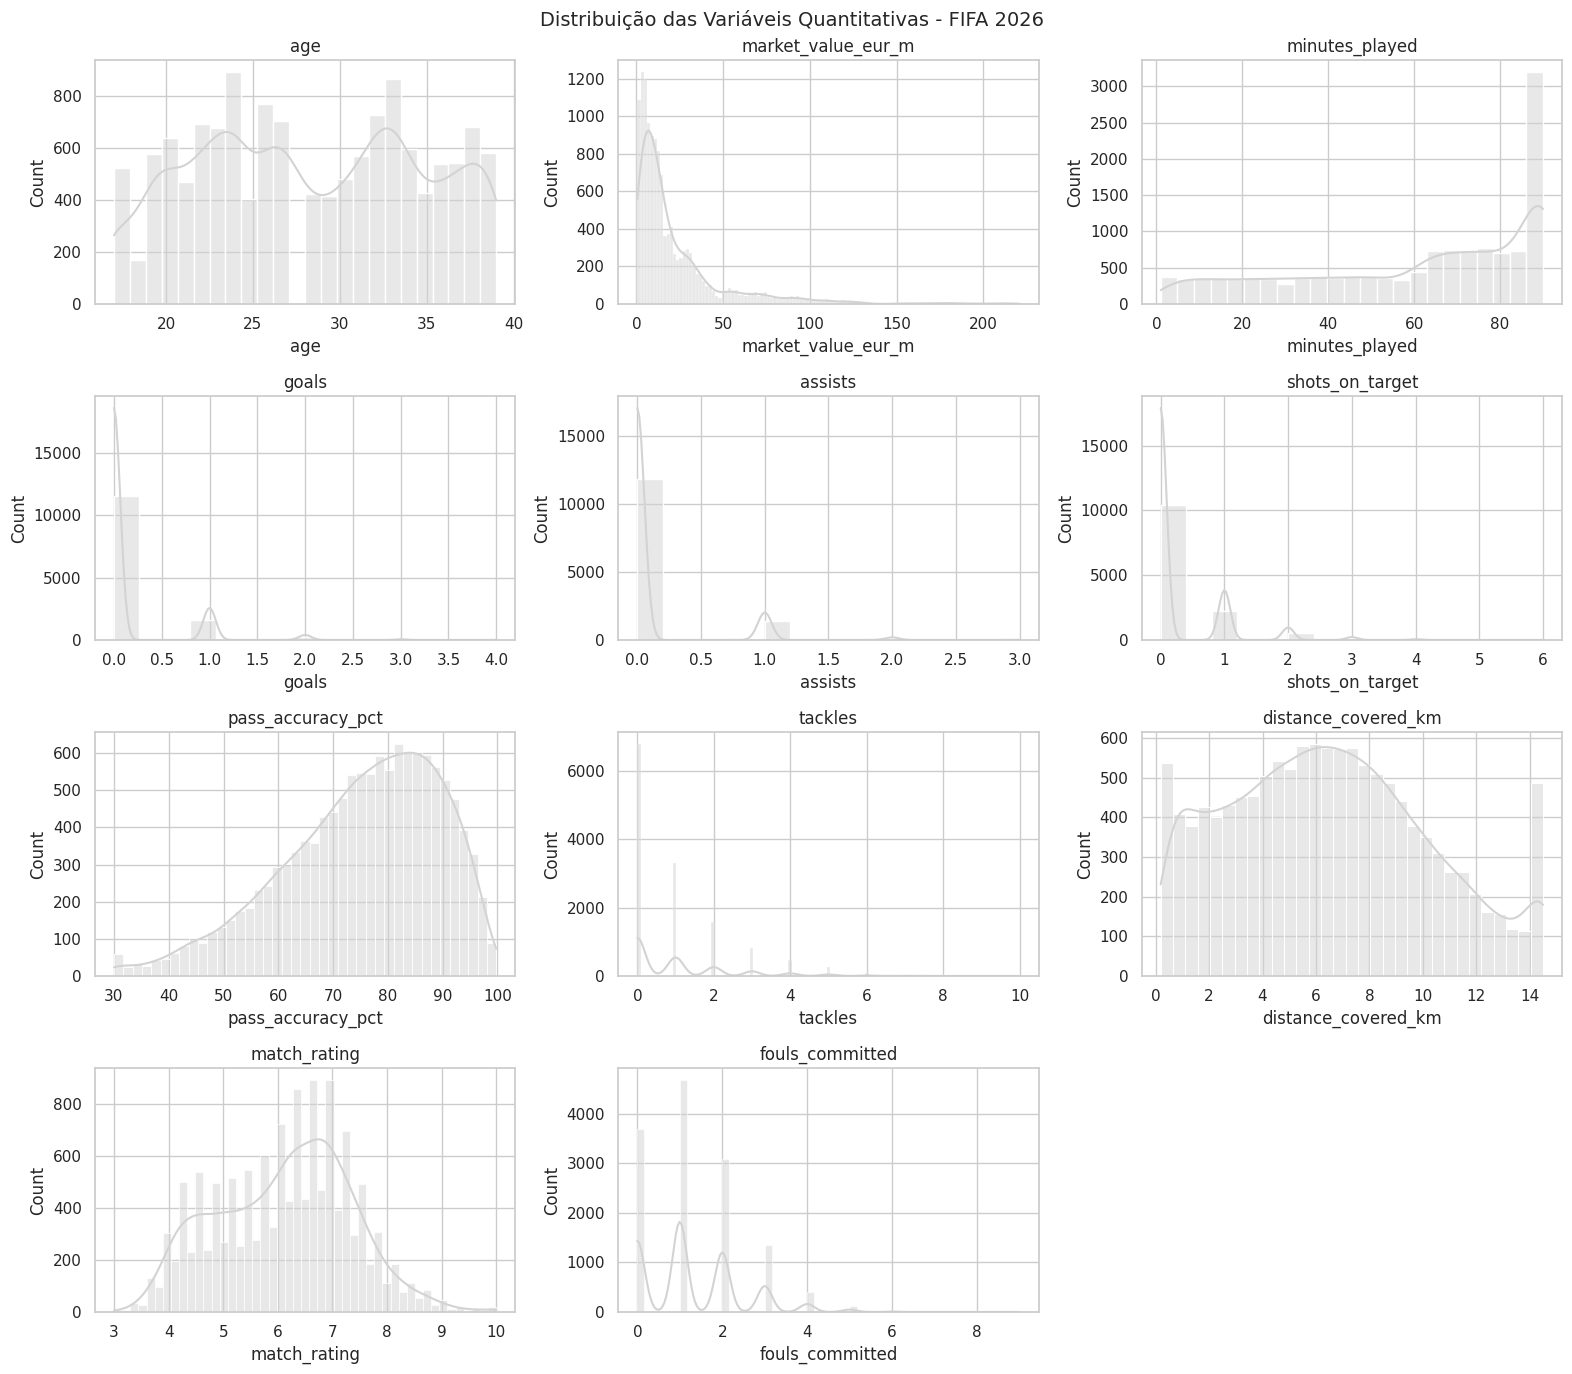

In [ ]:
fig, axes = plt.subplots(4, 3, figsize=(16, 14))
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, kde=True, color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)

for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle("Distribuição das Variáveis Quantitativas - FIFA 2026", fontsize=14)
plt.tight_layout()
plt.show()

Os histogramas confirmam os padrões observados na tabela descritiva. market_value_eur_m, goals, assists, shots_on_target e tackles apresentam forte concentração em valores baixos e cauda à direita, indicando assimetria positiva. pass_accuracy_pct apresenta maior concentração em valores altos, com cauda à esquerda. Já age, distance_covered_km e match_rating apresentam distribuições visualmente mais equilibradas.

#### Testes de Aderência

*Será se o colesterol segue uma distribuição normal?*

O **Shapiro-Wilk** como o teste de aderência mais usado pra normalidade, junto com o **QQ-Plot** como visualização de apoio. Vamos testar com `chol`.

Shapiro-Wilk — market_value_eur_m: estatística=0.6838, p-valor=1.778e-93
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


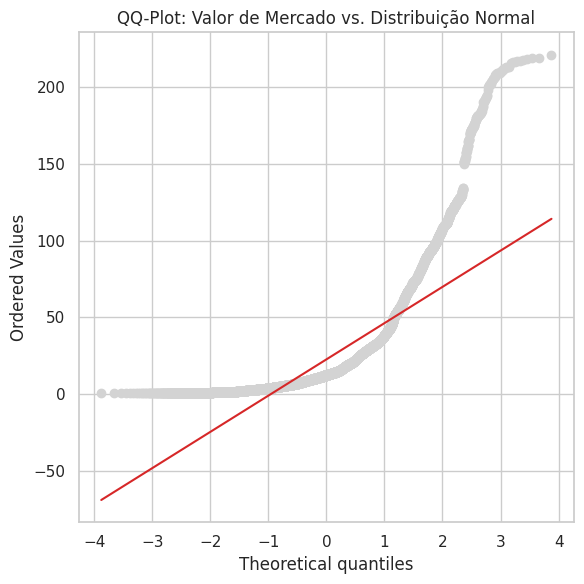

In [ ]:
stat_sw, p_valor_sw = stats.shapiro(df["market_value_eur_m"].dropna())

print(
    f"Shapiro-Wilk — market_value_eur_m: "
    f"estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}"
)

print(
    "Rejeita H0 (normalidade)?",
    "Sim" if p_valor_sw < 0.05 else "Não",
    "(alpha = 0.05)"
)

"""### QQ-Plot — colesterol"""

fig, ax = plt.subplots(figsize=(6, 6))

stats.probplot(
    df["market_value_eur_m"].dropna(),
    dist="norm",
    plot=ax
)

ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)

ax.set_title("QQ-Plot: Valor de Mercado vs. Distribuição Normal")

plt.tight_layout()
plt.show()

**Como ler:** se os pontos (roxo) seguissem a reta vermelha de perto, a variável seguiria uma normal. Pontos que se afastam da reta nas pontas indicam cauda mais pesada ou mais leve que a normal — coerente com o resultado do Shapiro-Wilk acima.

**Nota: cuidado com duas armadilhas de interpretação**

- **Tamanho da amostra e poder do teste:** é comum achar que "poucos dados" tornam mais fácil rejeitar a normalidade e é o contrário. Amostras **pequenas** têm **menos poder estatístico**, ou seja, tendem a *não* rejeitar mesmo quando os dados realmente não são normais. Já amostras **muito grandes** (milhares de linhas) deixam o teste sensível demais, rejeitando por desvios triviais. Com n≈303 (nem pequeno, nem enorme) e três evidências concordando — skewness alto, QQ-Plot afastado da reta, e Shapiro-Wilk rejeitando — o resultado é razoavelmente confiável, não um artefato do tamanho da amostra.
- **Como afirmar o resultado:** quando o teste **rejeita** H0 (nosso caso, p < 0.05), a afirmação correta é "temos evidência estatística **contra** a normalidade" que é uma conclusão forte. A frase "não podemos garantir normalidade" cabe no caso oposto: quando o teste **não rejeita** H0, já que a ausência de rejeição nunca prova que os dados são normais, só que não há evidência suficiente contra.

Como fica evidente, a distribuição não é normal, o valor de mercado intercta a distribuição normal em 2 pontos perceptíveis.

In [ ]:
resultados_shapiro = []

for col in VARS_QUANT:
    stat, p = stats.shapiro(df[col].dropna())

    resultados_shapiro.append({
        "variavel": col,
        "estatistica": round(stat, 4),
        "p_valor": round(p, 6),
        "rejeita_normalidade": p < 0.05
    })

pd.DataFrame(resultados_shapiro).set_index("variavel")

/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 13397.
  res = hypotest_fun_out(*samples, **kwds)
/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 13127.
  res = hypotest_fun_out(*samples, **kwds)
/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 12590.
  res = hypotest_fun_out(*samples, **kwds)
/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 12718.
  res = hypotest_fun_out(*samples, **kwds)


,estatistica,p_valor,rejeita_normalidade
variavel,,,
age,0.9544,0.0,True
market_value_eur_m,0.6838,0.0,True
minutes_played,0.8898,0.0,True
goals,0.4158,0.0,True
assists,0.3762,0.0,True
shots_on_target,0.5253,0.0,True
pass_accuracy_pct,0.9612,0.0,True
tackles,0.7364,0.0,True
distance_covered_km,0.9720,0.0,True


O teste de Shapiro-Wilk rejeitou a hipótese de normalidade para todas as variáveis quantitativas analisadas, com p-valores inferiores a 0,05. Entretanto, como o dataset possui mais de 13 mil observações, o teste é bastante sensível a pequenos desvios da normalidade. Por isso, os resultados foram avaliados em conjunto com histogramas, assimetria e QQ-Plot. Para market_value_eur_m, todas as evidências indicam forte afastamento da distribuição normal, com assimetria positiva elevada, curtose alta e grande desvio dos pontos em relação à reta teórica no QQ-Plot.

**ECDF — outra forma de ver a distribuição**

Diferente do histograma, a ECDF não depende de escolher o número de bins: para cada valor no eixo X, a curva mostra a **proporção acumulada** de observações menores ou iguais àquele valor. É especialmente útil pra comparar duas distribuições lado a lado — onde as curvas se distanciam mais é onde a diferença entre os grupos é mais perceptível.

Vamos ilustrar com uma única variável (`chol`, colesterol), só pra fixar como essa visualização se lê.

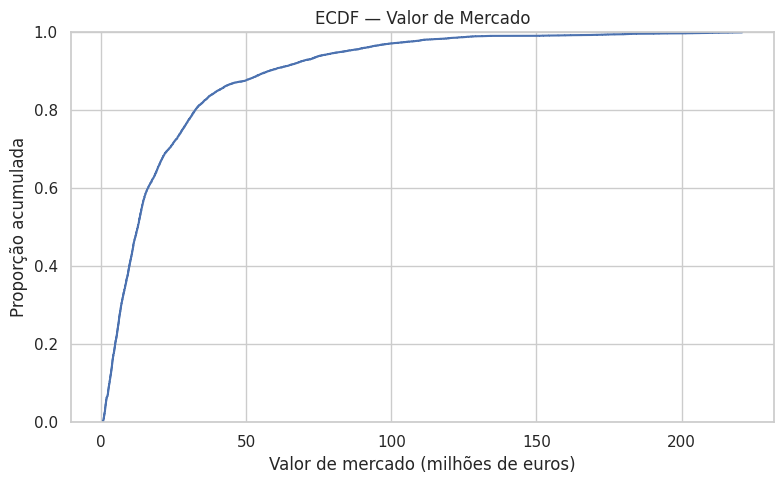

In [ ]:
plt.figure(figsize=(8, 5))

sns.ecdfplot(
    data=df,
    x="market_value_eur_m"
)

plt.title("ECDF — Valor de Mercado")
plt.xlabel("Valor de mercado (milhões de euros)")
plt.ylabel("Proporção acumulada")

plt.tight_layout()
plt.show()

**Como ler:** Por exemplo, se em x = 20 a curva estiver em 0.70, isso significa:

aproximadamente 70% das observações possuem valor de mercado de até 20 milhões de euros.

### Métricas de Tendêncial Central

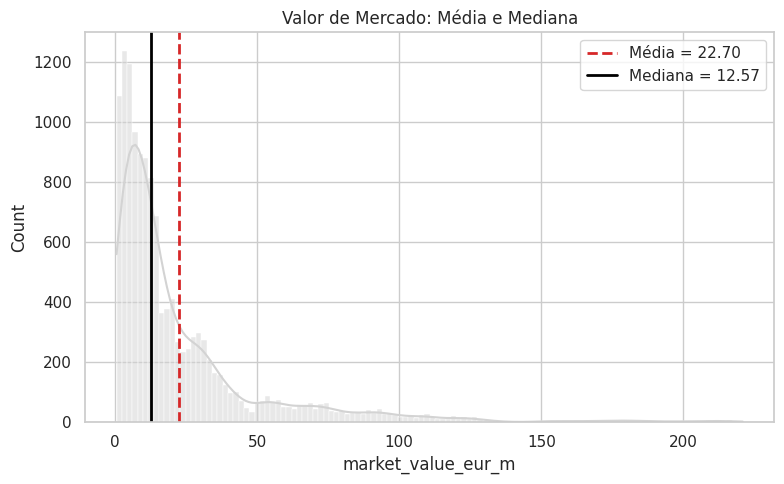

In [ ]:
media_valor = df["market_value_eur_m"].mean()
mediana_valor = df["market_value_eur_m"].median()

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="market_value_eur_m",
    kde=True,
    color=COR_NEUTRA
)

plt.axvline(
    media_valor,
    color=COR_ALERTA,
    linestyle="--",
    linewidth=2,
    label=f"Média = {media_valor:.2f}"
)

plt.axvline(
    mediana_valor,
    color="black",
    linestyle="-",
    linewidth=2,
    label=f"Mediana = {mediana_valor:.2f}"
)

plt.title("Valor de Mercado: Média e Mediana")
plt.legend()

plt.tight_layout()
plt.show()

### Dispersão

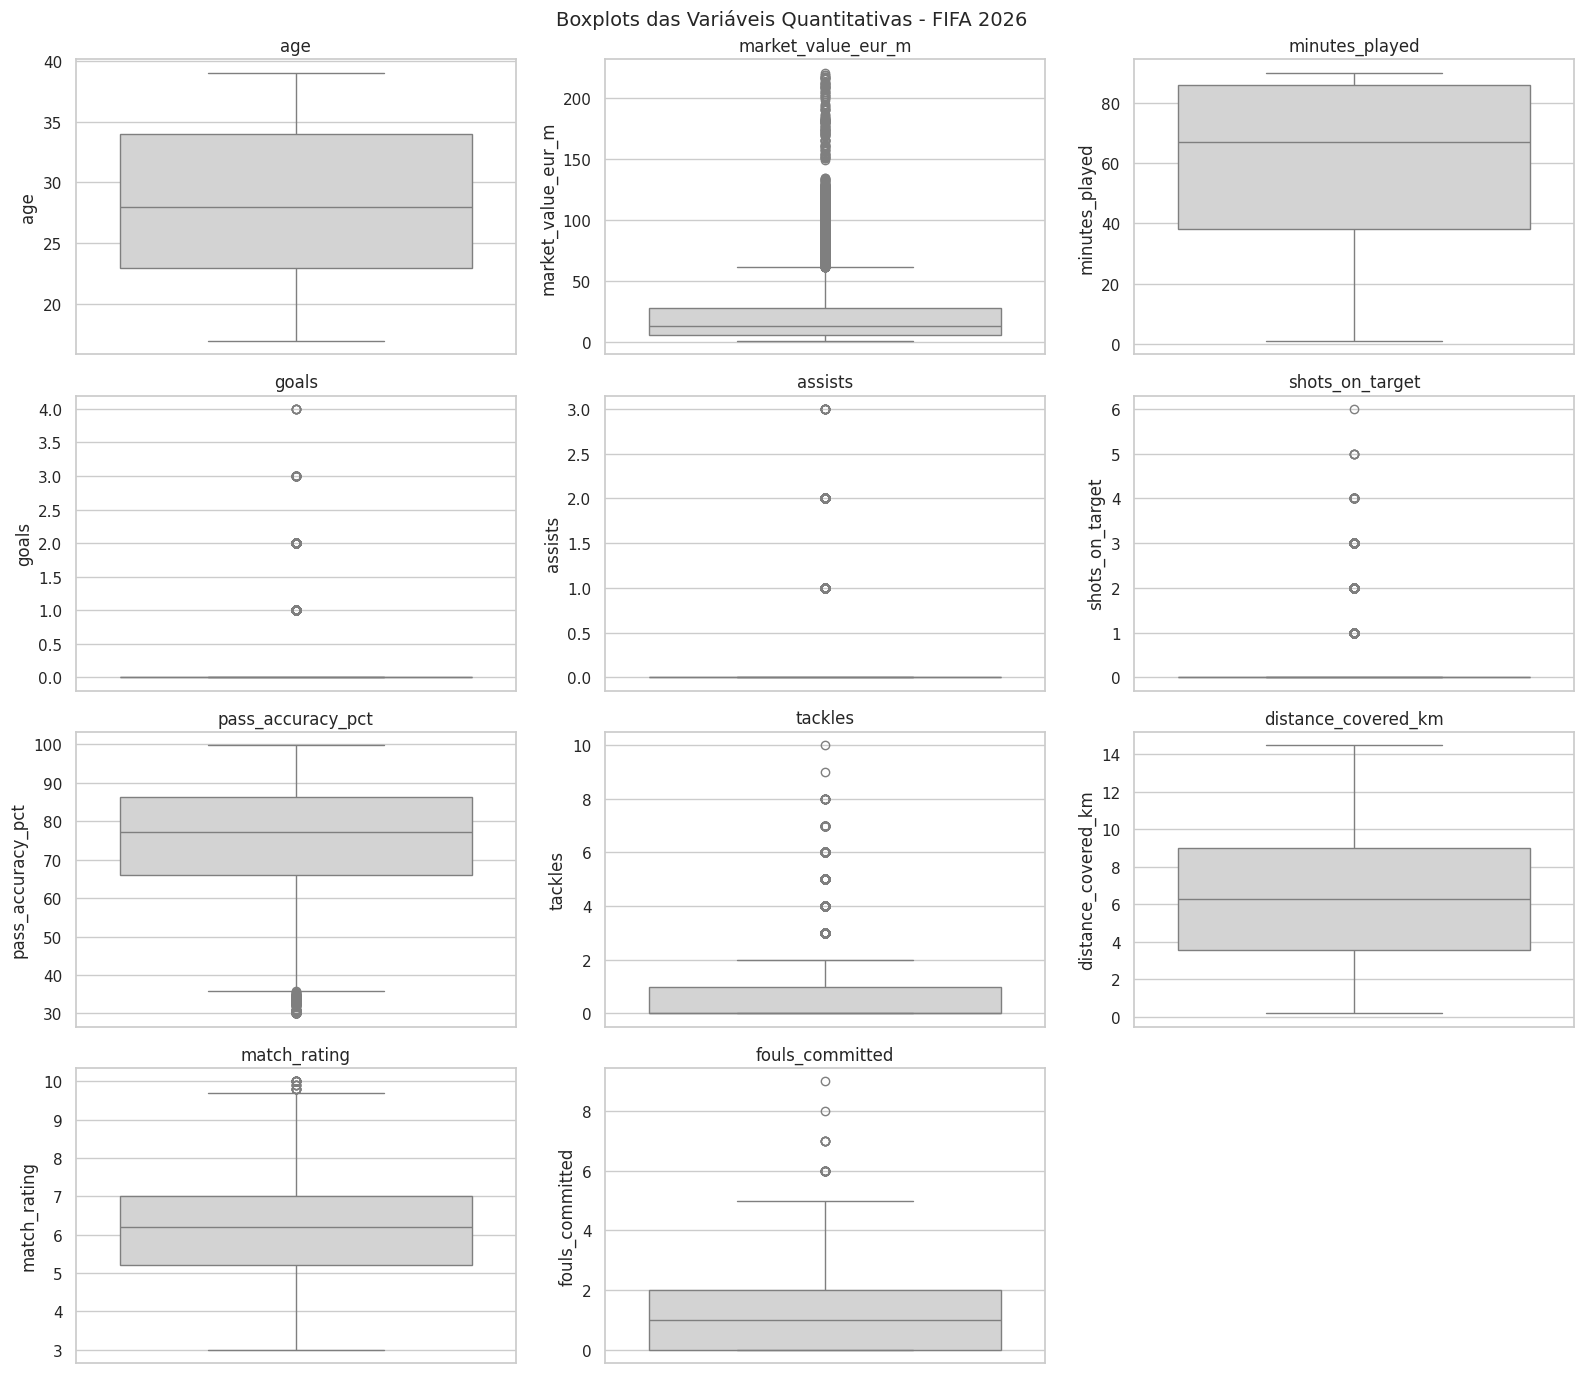

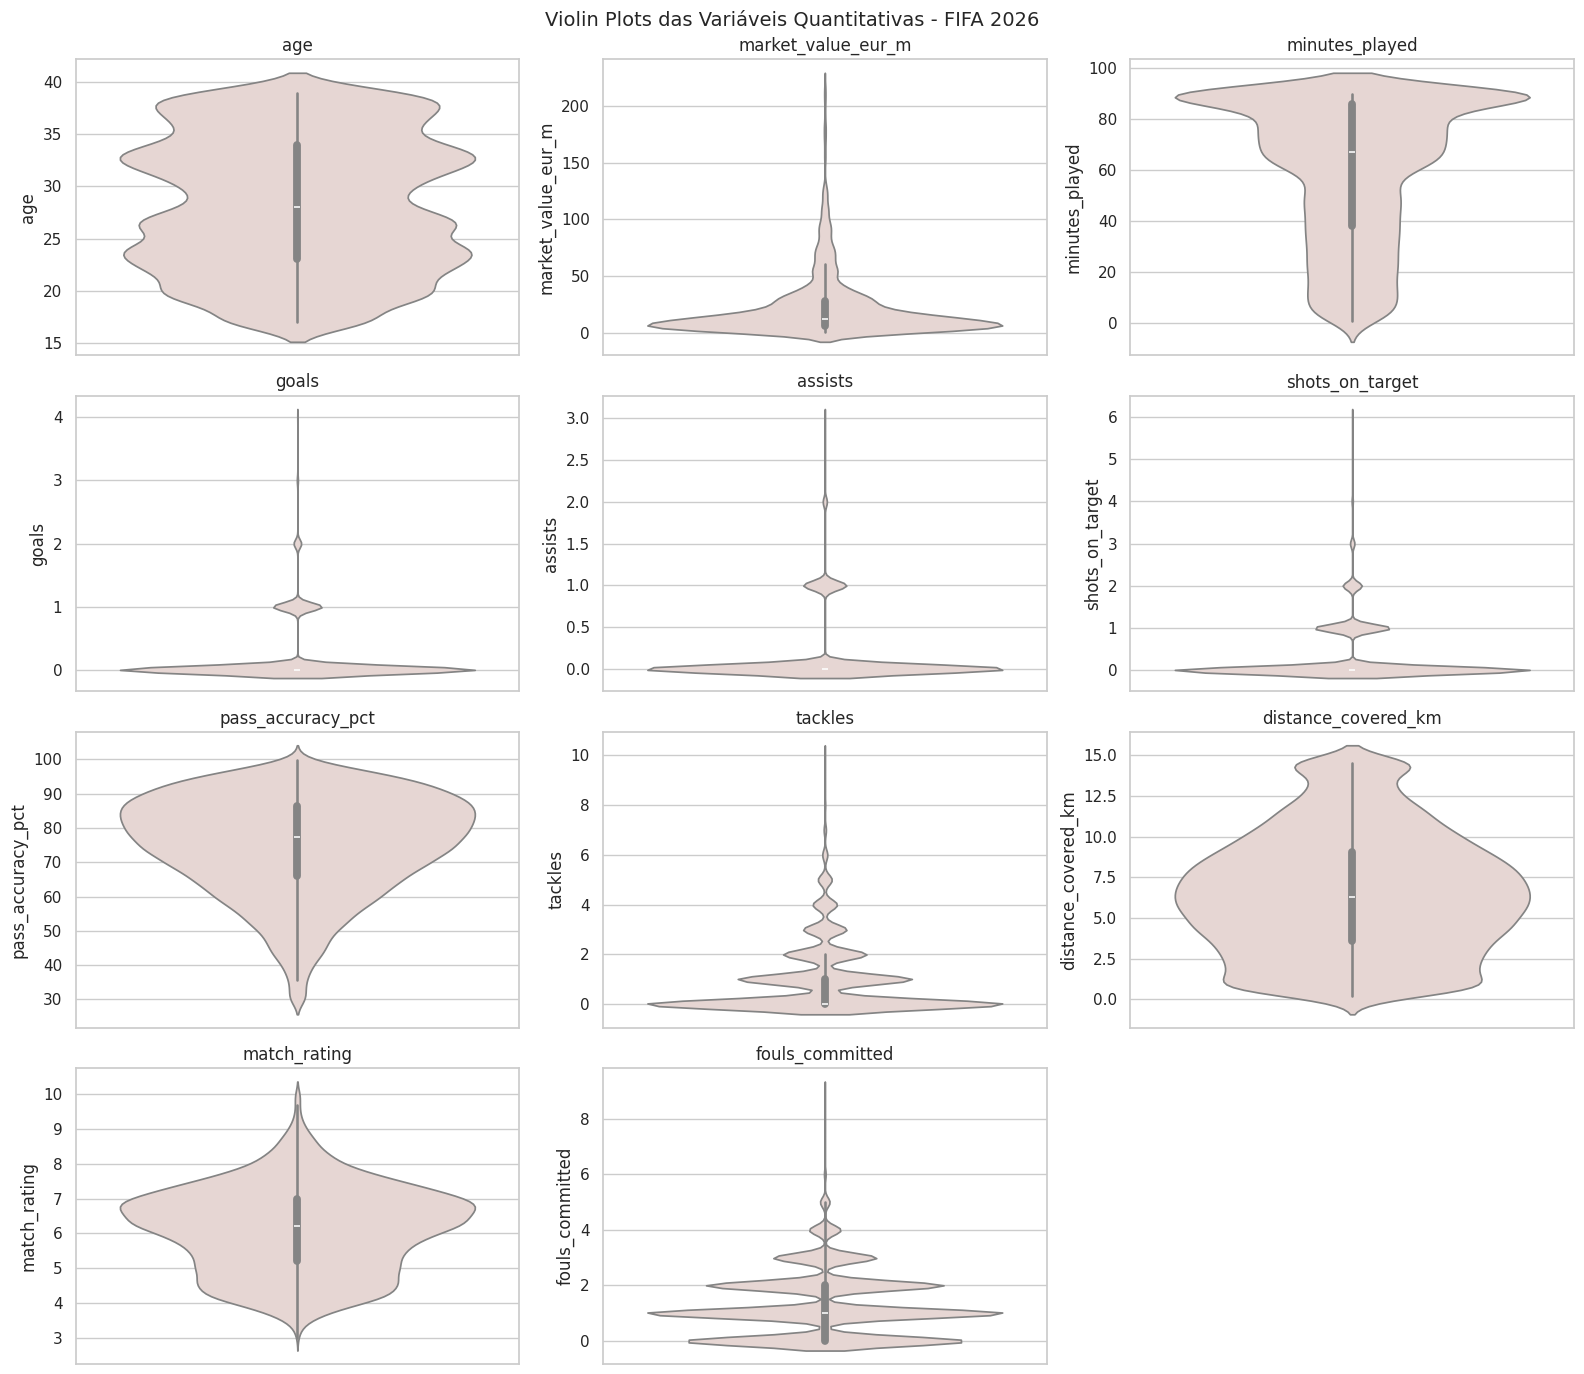

In [ ]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T

dispersao["IQR"] = (
    df[VARS_QUANT].quantile(0.75)
    - df[VARS_QUANT].quantile(0.25)
)

dispersao.round(2)
### Boxplot e Violin Plot das Variáveis Quantitativas
fig, axes = plt.subplots(4, 3, figsize=(16, 14))
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)

for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle("Boxplots das Variáveis Quantitativas - FIFA 2026", fontsize=14)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(4, 3, figsize=(16, 14))
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.violinplot(data=df, y=col, color=COR_CONTEXTO, ax=axes[i])
    axes[i].set_title(col)

for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle("Violin Plots das Variáveis Quantitativas - FIFA 2026", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável mostra uma caixa (IQR) nitidamente mais alta ou mais baixa entre "Normal" e "Cardíaco"? Isso já é um indício — antes mesmo da análise bivariada formal — de que essa variável pode ajudar a diferenciar as duas classes.

Como a gente ja viu antes, o market_value_eur_m apresenta muitos valores acima do limite superior do boxplot e uma longa cauda à direita no violin plot, coerente com sua elevada assimetria positiva. goals, assists, shots_on_target e tackles também apresentam forte concentração em valores baixos e alguns valores elevados classificados estatisticamente como outliers. pass_accuracy_pct apresenta alguns valores extremos na parte inferior da distribuição. Já age, minutes_played e distance_covered_km apresentam distribuições com menor presença de valores extremos. É importante destacar que um outlier estatístico não representa necessariamente um erro: em variáveis como gols, assistências ou valor de mercado, valores raros podem ser legítimos dentro do contexto do futebol, Como a senhora mencionou em aula.

## 4. Tratamento de Dados Ausentes e Outliers

Agora que já vimos o retrato estatístico "antes" (Seção 3), temos a informação que faltava pra decidir como tratar tanto os dados ausentes (`ca`, `thal`) quanto os outliers das variáveis quantitativas. Depois do tratamento, vamos rodar a estatística descritiva mais uma vez ("depois") pra confirmar o efeito das escolhas e fechar o ciclo iterativo que começamos lá na abertura.

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [ ]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers
age,6.50,50.50,0.0
market_value_eur_m,-27.23,61.03,1201.0
minutes_played,-34.00,158.00,0.0
goals,0.00,0.00,1878.0
assists,0.00,0.00,1550.0
shots_on_target,0.00,0.00,2971.0
pass_accuracy_pct,35.80,116.60,119.0
tackles,-1.50,2.50,1710.0
distance_covered_km,-4.64,17.23,0.0
match_rating,2.50,9.70,25.0


### Visualizando os Outliers

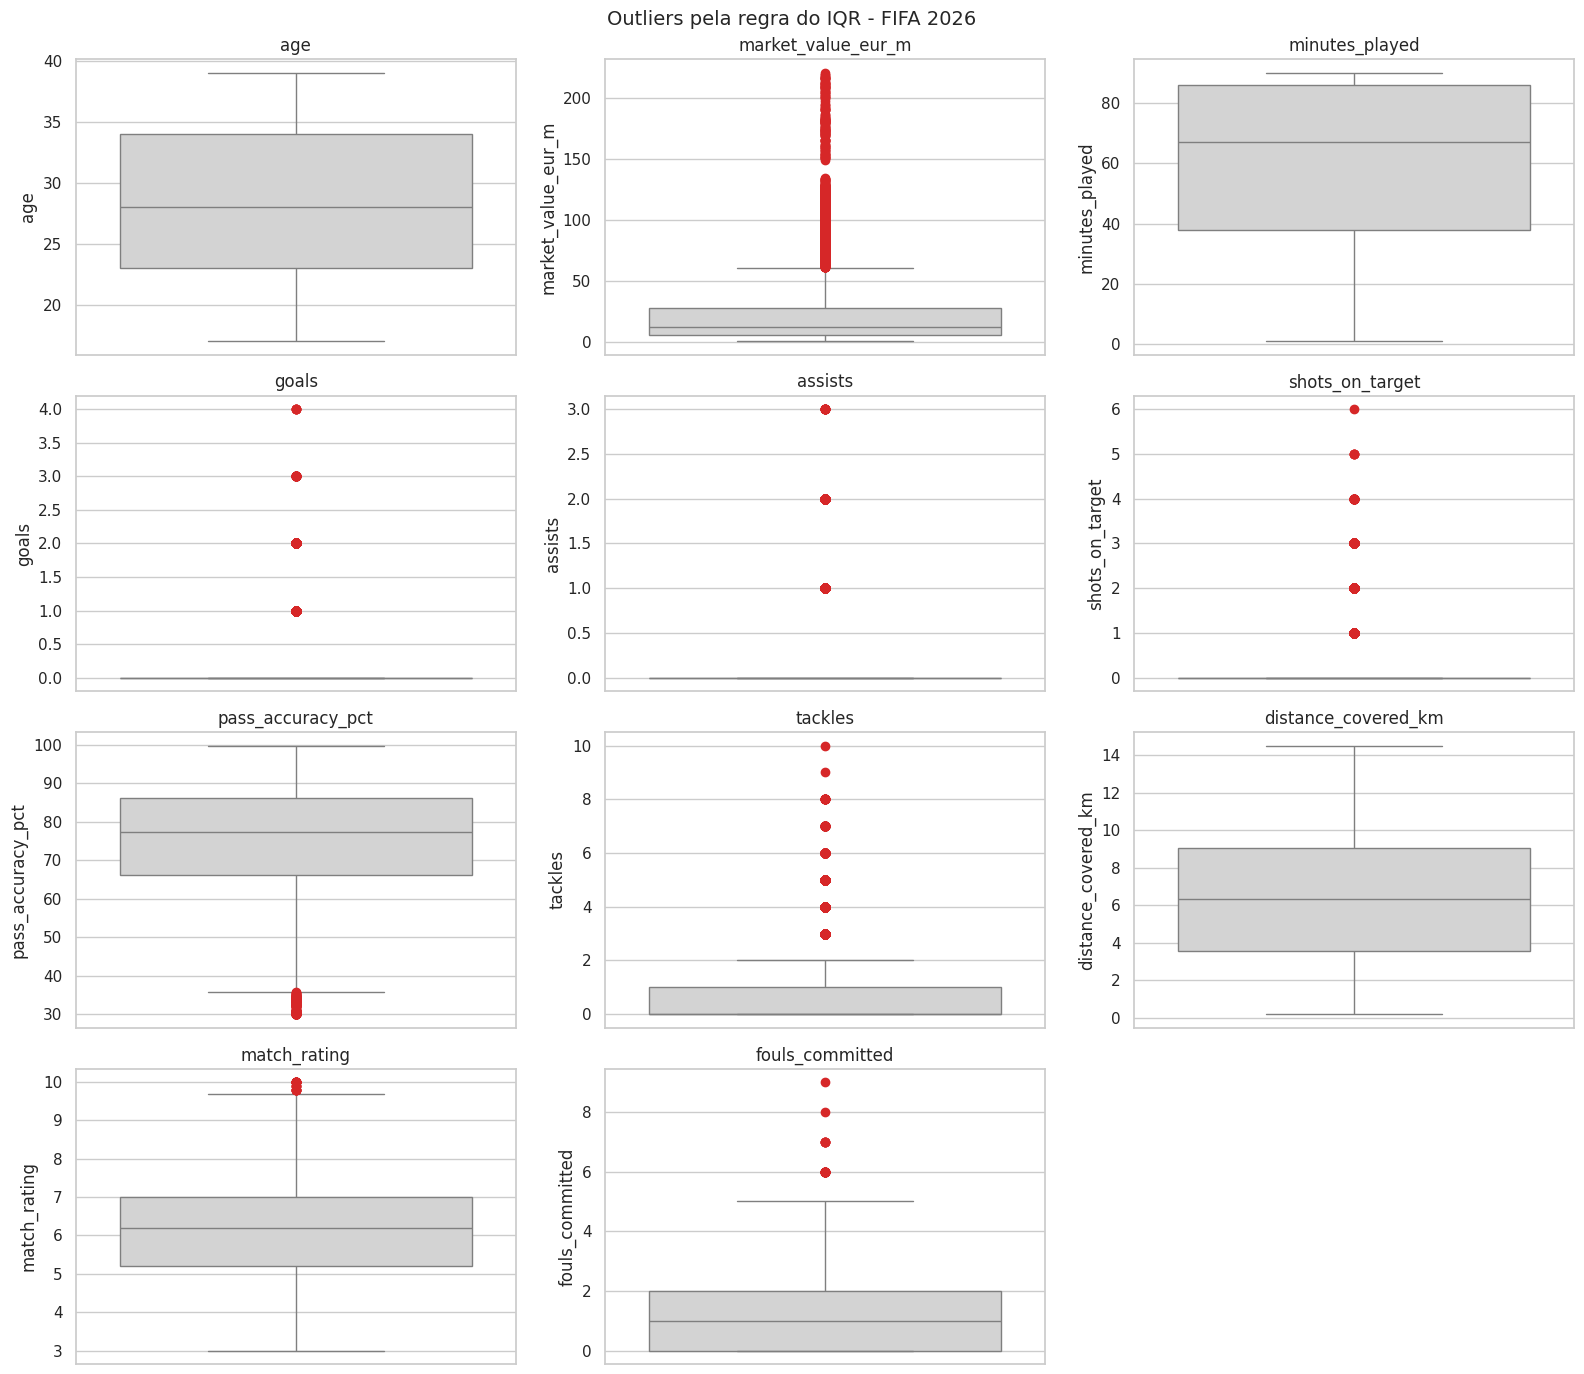

In [ ]:
fig, axes = plt.subplots(4, 3, figsize=(16, 14))
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(
        data=df,
        y=col,
        color=COR_NEUTRA,
        flierprops=dict(
            markerfacecolor=COR_ALERTA,
            markeredgecolor=COR_ALERTA,
            marker="o"
        ),
        ax=axes[i]
    )

    axes[i].set_title(col)

for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle(
    "Outliers pela regra do IQR - FIFA 2026",
    fontsize=14
)

plt.tight_layout()
plt.show()

**Pra discutir:** o slide 26 da aula 9 classifica outliers em três tipos, cada um com um tratamento recomendado:

| Tipo | Cenário | O que fazer? |
|---|---|---|
| Estatístico | Legítimo | Manter / Transformar |
| De domínio | Viola regra de negócio ou condições físicas | Investigar! |
| Erros de dados | Falhas | Corrigir se possível / Remover como última opção |

Olhando os outliers encontrados (principalmente em `chol` e `oldpeak`): eles parecem fisiologicamente plausíveis (pacientes reais podem ter colesterol muito alto), ou parecem violar algum limite físico conhecido? Isso muda qual das três categorias se aplica — e, consequentemente, se devemos manter, transformar ou remover.

### Decidindo o Tratamento dos Dados Ausentes

Reunindo o que já discutimos: o mecanismo mais provável para `ca`/`thal` é MAR ou MCAR (não MNAR), e o volume é pequeno (poucas linhas em ~300). Com essas duas informações juntas, a decisão pragmática é remover as linhas afetadas — o risco de viés é baixo (mecanismo provavelmente não depende do próprio valor ausente) e o custo de perder ~2% das linhas é pequeno.

**RESPOSTA**

Os outliers encontrados não devem ser removidos automaticamente. Em variáveis como valor de mercado, gols, assistências, finalizações e desarmes, valores elevados podem representar observações raras, porém plausíveis dentro do domínio do futebol. Além disso, como já foram identificadas possíveis inconsistências no próprio dataset, não existe informação suficiente para determinar quais valores extremos representam erros de dados. Portanto, os outliers serão mantidos, evitando alterações arbitrárias na base.

In [ ]:
linhas_antes = df.shape[0]
df_antes = df.copy()
df = df.dropna(subset=["ca", "thal"]).reset_index(drop=True)
linhas_depois = df.shape[0]

print(f"Linhas antes: {linhas_antes} | Linhas depois: {linhas_depois} | Removidas: {linhas_antes - linhas_depois}")

Linhas antes: 13397 | Linhas depois: 13397 | Removidas: 0


In [ ]:
df_antes = df.copy()

In [ ]:
cols_imputar = [
    "market_value_eur_m",
    "pass_accuracy_pct",
    "distance_covered_km"
]

for col in cols_imputar:
    df[col] = df[col].fillna(df[col].median())

In [ ]:
df[cols_imputar].isna().sum()

,0
market_value_eur_m,0
pass_accuracy_pct,0
distance_covered_km,0


Decidi imputar pela mediana nas variáveis, pois ela é menos sensível a valores extremos e À assimetria.

### Decidindo o Tratamento dos Outliers

Diferente dos ausentes, aqui **não vamos remover automaticamente**. Pelos valores encontrados (dentro de faixas clinicamente plausíveis, ainda que raras), a classificação mais provável é **"Estatístico"**, outliers legítimos, não erros de coleta. Sendo assim, o tratamento recomendado nesse caso é **manter** (a informação é real e pode ser clinicamente relevante — por exemplo, exatamente os pacientes com colesterol mais extremo podem ser os de maior risco) ou, se for necessário para alguma técnica estatística específica mais à frente (ex: métodos sensíveis à assimetria), **transformar**.

Vamos manter os valores originais por enquanto, mas ilustrar como ficaria uma transformação logarítmica em `chol` — útil caso, mais adiante em análises futuras, a assimetria atrapalhe algum teste ou modelo.

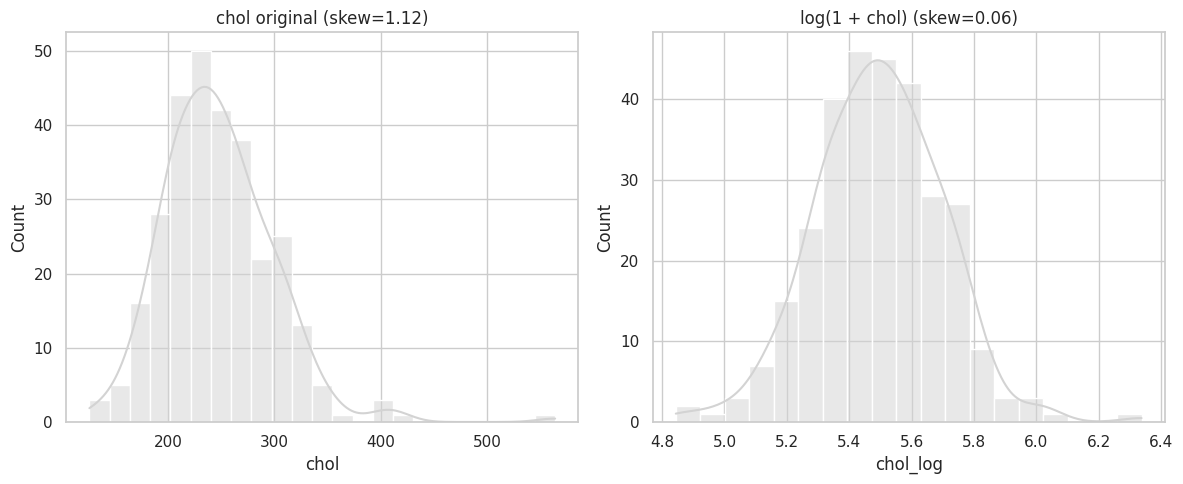

In [ ]:
df["chol_log"] = np.log1p(df["chol"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df, x="chol", kde=True, color=COR_NEUTRA, ax=axes[0])
axes[0].set_title(f"chol original (skew={df['chol'].skew():.2f})")

sns.histplot(data=df, x="chol_log", kde=True, color=COR_NEUTRA, ax=axes[1])
axes[1].set_title(f"log(1 + chol) (skew={df['chol_log'].skew():.2f})")

plt.tight_layout()
plt.show()

**Pra discutir:** a transformação logarítmica reduziu visivelmente a assimetria? Mantivemos `chol_log` só como demonstração, mas não vamos usá-la nas próximas seções. A ideia foi mostrar como opção se fosse o objetivo de, por exemplo, alimentar um teste paramétrico que exige normalidade.

**Nota para quando vocês replicarem no dataset de vocês:** nem todo outlier deve ser removido. Antes de decidir, classifiquem: é um valor estatisticamente raro mas plausível (manter/transformar), viola alguma regra física ou de negócio (investigar antes de decidir), ou é claramente um erro de digitação/coleta (corrigir ou remover)?

**RESPOSTA**

Como a senhora mencionou na nota acima, decidi não remover os valores extremos de algumas variáveis, pois elas podem sim representar dados reais no meio futebolístico.

## 5. Estatística Descritiva pt 2

Fechando o ciclo iterativo: tratamos os ausentes e decidimos manter os outliers. Agora rodamos a mesma bateria de estatísticas da Seção 3 para comparar diretamente com o "antes".

In [ ]:
desc_depois = df[VARS_QUANT].describe().T
desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="Blues", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
age,28.27,28.00,6.44,17.00,39.00,0.01,-1.17
market_value_eur_m,22.49,12.57,28.25,0.57,220.87,2.88,10.84
minutes_played,60.00,67.00,27.65,1.00,90.00,-0.61,-0.92
goals,0.16,0.00,0.44,0.00,4.00,3.02,10.58
assists,0.13,0.00,0.37,0.00,3.00,3.06,10.13
shots_on_target,0.29,0.00,0.62,0.00,6.00,2.55,7.83
pass_accuracy_pct,75.24,77.30,13.89,30.00,99.80,-0.72,0.19
tackles,0.98,0.00,1.36,0.00,10.00,1.76,3.33
distance_covered_km,6.48,6.31,3.61,0.19,14.50,0.31,-0.55
match_rating,6.12,6.20,1.23,3.00,10.00,-0.03,-0.51


### Comparando "antes"x "depois""



In [ ]:
comparacao = pd.DataFrame({
    "skewness_antes": desc["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"]
})

comparacao["delta_skewness"] = (
    comparacao["skewness_depois"]
    - comparacao["skewness_antes"]
).round(3)

comparacao["delta_kurtosis"] = (
    comparacao["kurtosis_depois"]
    - comparacao["kurtosis_antes"]
).round(3)

comparacao.round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
age,0.010,0.010,-1.173,-1.173,0.000,0.000
market_value_eur_m,2.837,2.876,10.552,10.843,0.039,0.292
minutes_played,-0.614,-0.614,-0.919,-0.919,0.000,0.000
goals,3.017,3.017,10.584,10.584,0.000,0.000
assists,3.065,3.065,10.132,10.132,0.000,0.000
shots_on_target,2.547,2.547,7.832,7.832,0.000,0.000
pass_accuracy_pct,-0.672,-0.720,-0.018,0.191,-0.048,0.209
tackles,1.763,1.763,3.332,3.332,0.000,0.000
distance_covered_km,0.290,0.306,-0.680,-0.554,0.015,0.126
match_rating,-0.031,-0.031,-0.514,-0.514,0.000,0.000


**Pra discutir:** os valores mudaram muito? Fazia sentido esperar uma diferença grande, considerando que removemos só ~2% das linhas e decidimos **não** alterar nenhum outlier? Esse resultado (pouca mudança) é, na verdade, uma confirmação de que o tratamento foi conservador — não um sinal de que ele não fez nada de útil.

**RESPOSTA**

O trtamento que fiz foi 'conservador'. Os outliers foram mantidos e os valores ausentes foram preenchidos pela mediana, como citei anteriormente. Por isso que é esperado que se matenha semelhante ao que observamos anteriormente.


**O colesterol ainda rejeita normalidade?**

Vamos rodar o mesmo Shapiro-Wilk da Seção 3, agora nos dados tratados.

In [ ]:
stat_sw_depois, p_valor_sw_depois = stats.shapiro(
    df["market_value_eur_m"].dropna()
)

print(
    f"Shapiro-Wilk (antes) — market_value_eur_m: "
    f"estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}"
)

print(
    f"Shapiro-Wilk (depois) — market_value_eur_m: "
    f"estatística={stat_sw_depois:.4f}, p-valor={p_valor_sw_depois:.4g}"
)

Shapiro-Wilk (antes) — market_value_eur_m: estatística=0.6838, p-valor=1.778e-93
Shapiro-Wilk (depois) — market_value_eur_m: estatística=0.6795, p-valor=2.563e-94


/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 13397.
  res = hypotest_fun_out(*samples, **kwds)


**Visualizando antes x depois, lado a lado**

Vamos sobrepor as distribuições de duas variáveis que mais chamaram atenção na Seção 4 (`chol` e `oldpeak`), comparando a versão original (`df_antes`) com a tratada (`df`).

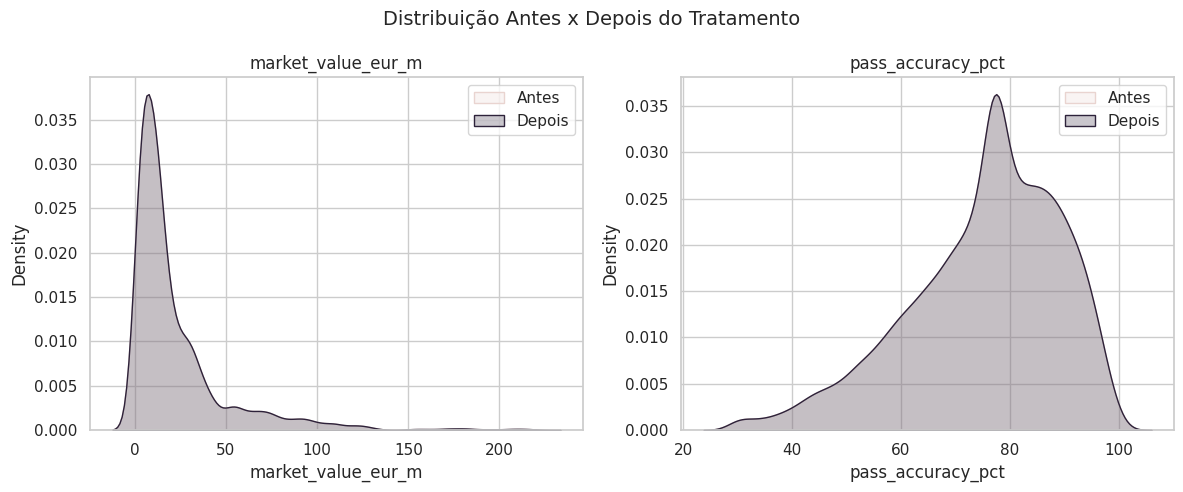

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, col in zip(
    axes,
    ["market_value_eur_m", "pass_accuracy_pct"]
):
    sns.kdeplot(
        df_antes[col].dropna(),
        color=COR_CONTEXTO,
        fill=True,
        label="Antes",
        ax=ax
    )

    sns.kdeplot(
        df[col],
        color=COR_DESTAQUE,
        fill=True,
        label="Depois",
        ax=ax
    )

    ax.set_title(col)
    ax.legend()

fig.suptitle(
    "Distribuição Antes x Depois do Tratamento",
    fontsize=14
)

plt.tight_layout()
plt.show()

**Pra discutir:** as curvas "antes" e "depois" praticamente se sobrepõem? Isso é o esperado aqui, já que removemos poucas linhas e não tocamos nos outliers.

Guardem essa observação: em datasets onde o volume de ausentes/outliers for maior, essa mesma comparação pode mostrar uma diferença bem mais visível e sempre que essa checagem "antes x depois" que confirma (ou não) que o tratamento teve o efeito esperado, em vez de assumir isso às cegas.

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Agora focaremos na avaliação de frequência e desbalanceamento das variáveis qualitativas.




#### Frequências absolutas e relativas

In [ ]:
for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)

    print(f"\n--- {col} ---")
    print(
        pd.concat(
            [
                freq_abs.rename("absoluta"),
                freq_rel.rename("relativa")
            ],
            axis=1
        )
    )


--- nationality ---
               absoluta  relativa
nationality                      
England            1638     0.122
France             1280     0.096
Brazil             1109     0.083
Germany            1089     0.081
Netherlands         984     0.073
Spain               966     0.072
Argentina           646     0.048
Italy               568     0.042
Portugal            566     0.042
Morocco             453     0.034
Belgium             342     0.026
Uruguay             294     0.022
Norway              285     0.021
United States       235     0.018
Sweden              224     0.017
Turkey              222     0.017
Unknown             218     0.016
Ukraine             184     0.014
Denmark             178     0.013
Nigeria             175     0.013
Ghana               172     0.013
Senegal             170     0.013
Poland              117     0.009
South Korea         117     0.009
Colombia            112     0.008
Croatia             109     0.008
Cameroon            106    

#### Visualizando as frequências

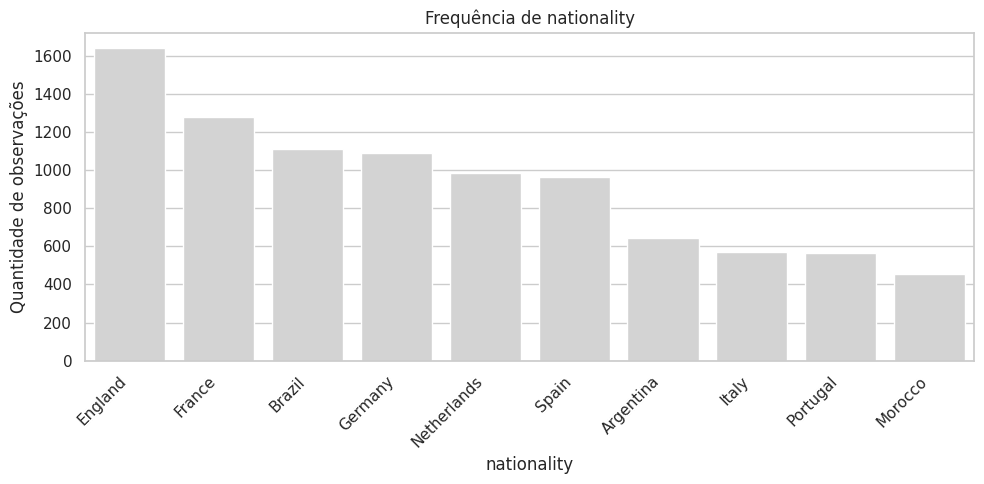

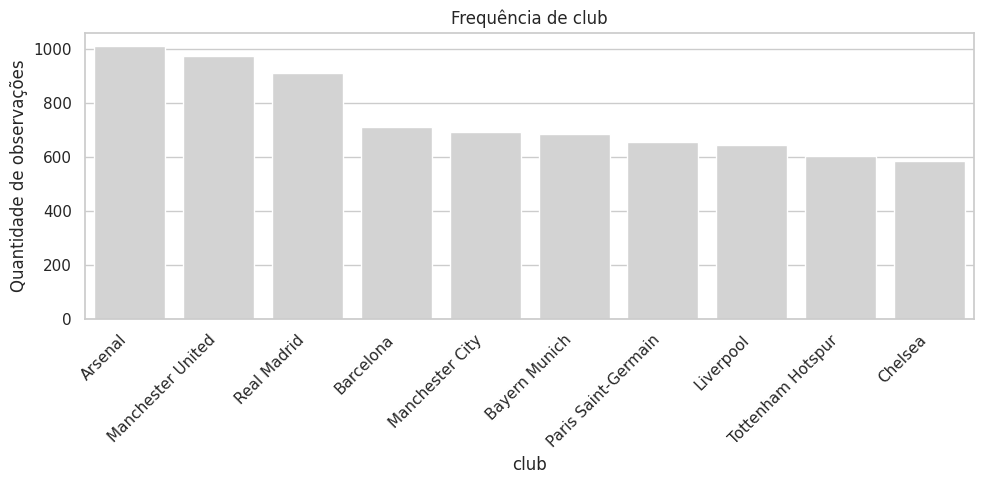

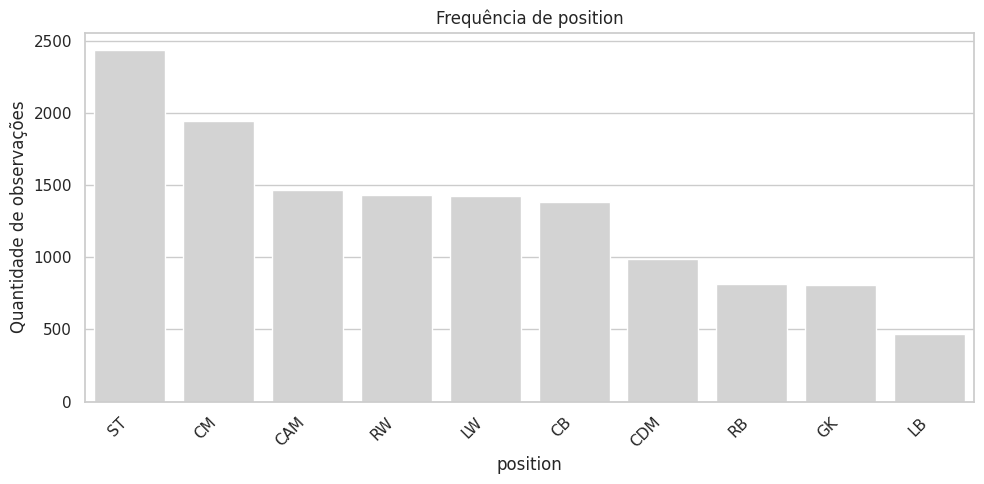

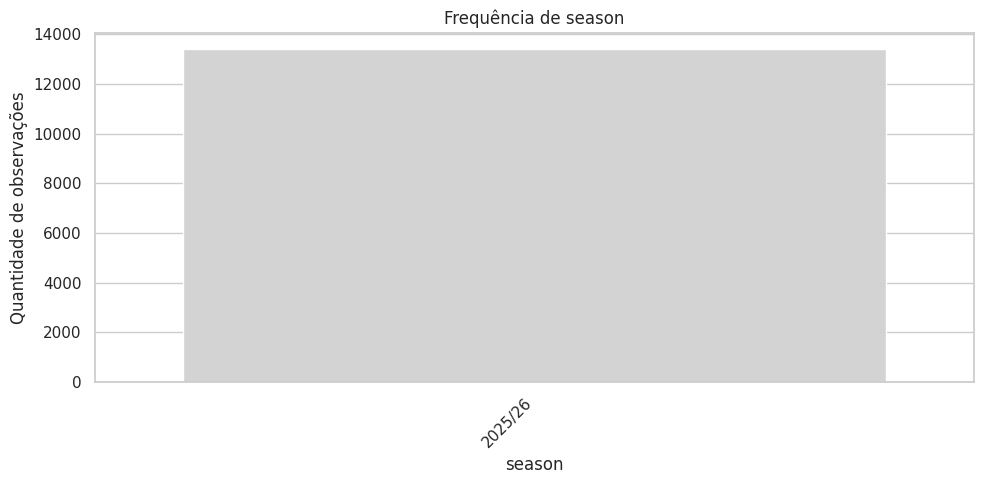

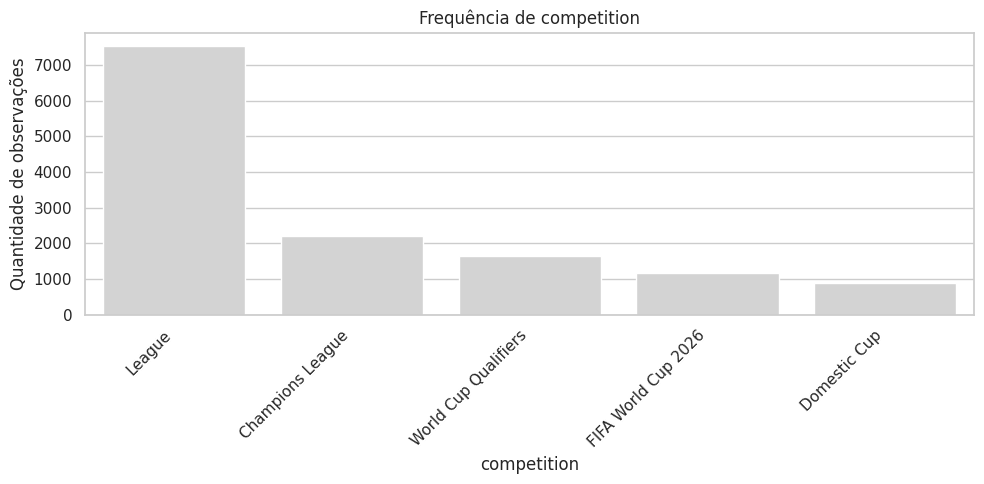

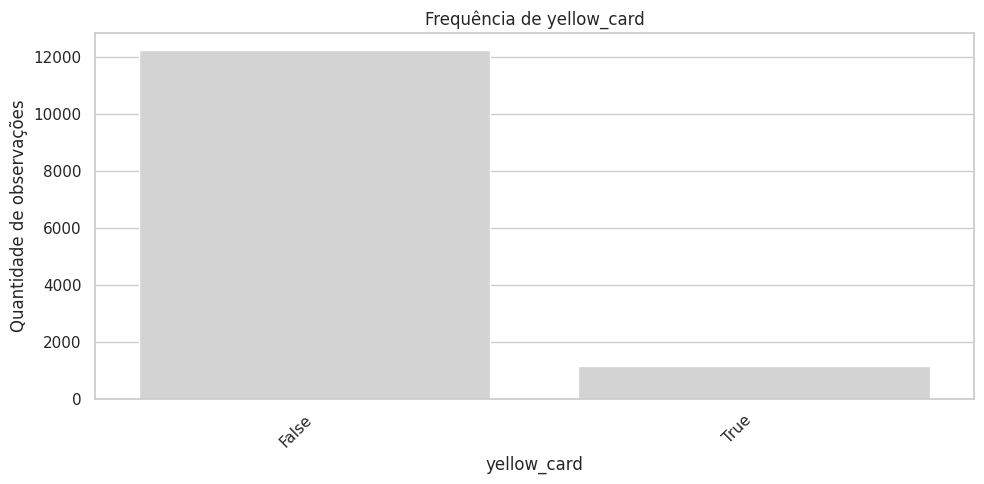

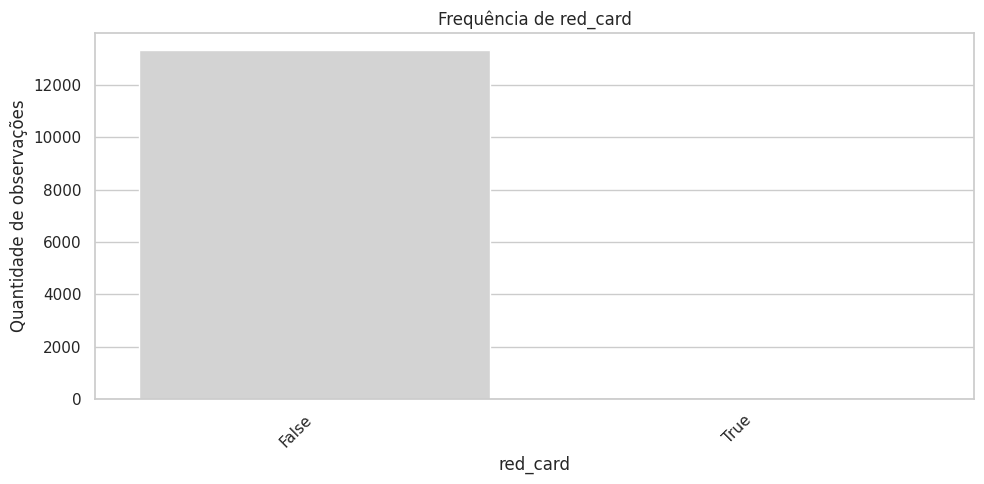

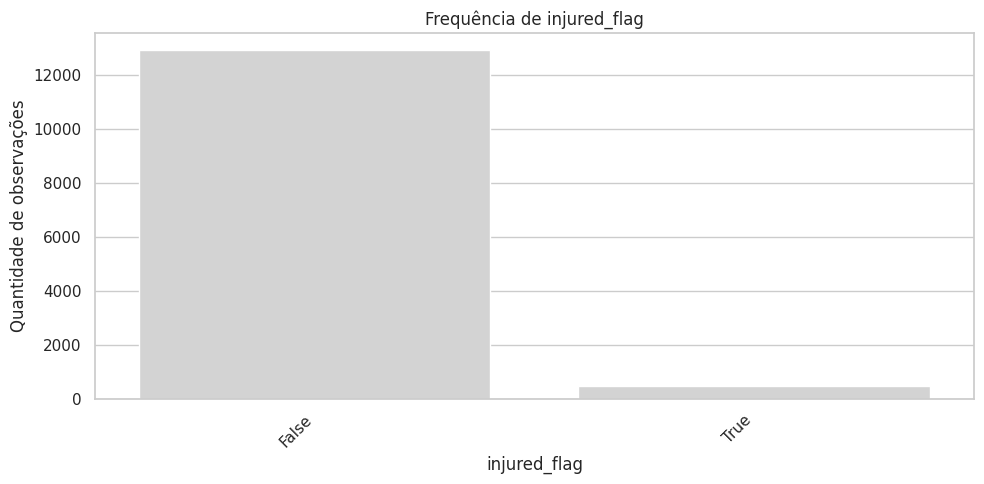

In [ ]:
for col in VARS_QUALI:

    plt.figure(figsize=(10, 5))

    contagem = df[col].value_counts()

    # Para variáveis com muitas categorias,
    # mostramos apenas as 10 mais frequentes
    if len(contagem) > 10:
        contagem = contagem.head(10)

    sns.barplot(
        x=contagem.index,
        y=contagem.values,
        color=COR_NEUTRA
    )

    plt.title(f"Frequência de {col}")
    plt.ylabel("Quantidade de observações")
    plt.xlabel(col)
    plt.xticks(rotation=45, ha="right")

    plt.tight_layout()
    plt.show()

**Pra discutir:** alguma variável qualitativa está bem desbalanceada (uma categoria dominando quase todas as observações)? Isso pode impactar como vamos interpretar cruzamentos com essa variável mais na frente na análise bivariada.

OBS

Eu decidi tirar o formato 2x4 pois tem muita coisa, ai ia ficar ilegível.

#### Desbalanceamento entre Classes

- **Razão de desbalanceamento** — # classe majoritária / # classe minoritária (quanto maior, mais desbalanceado).
- **Entropia de Shannon normalizada** — 1 = perfeitamente balanceado, 0 = uma classe domina tudo.

Vamos aplicar as duas em todas as qualitativas, incluindo o próprio alvo `doenca_cardiaca`.

In [ ]:
from scipy.stats import entropy

def metrica_desbalanceamento(serie):

    contagens = serie.value_counts()

    razao = contagens.max() / contagens.min()

    props = contagens / contagens.sum()

    n_classes = len(contagens)

    ent_normalizada = (
        entropy(props, base=2) / np.log2(n_classes)
        if n_classes > 1
        else np.nan
    )

    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3)
    })

In [ ]:
pd.DataFrame({
    col: metrica_desbalanceamento(df[col])
    for col in VARS_QUALI
}).T

,n_classes,razao_desbalanceamento,entropia_normalizada
nationality,41.0,32.12,0.850
club,47.0,19.76,0.882
position,11.0,10.40,0.944
season,1.0,1.00,NaN
competition,5.0,8.59,0.788
yellow_card,2.0,10.53,0.425
red_card,2.0,190.39,0.047
injured_flag,2.0,26.12,0.228


**Pra discutir:** alguma variável está com entropia bem próxima de 0 (bem desbalanceada)? E o próprio alvo `doenca_cardiaca` — está balanceado o suficiente pra não distorcer a análise bivariada e um eventual modelo mais à frente?

**RESPOSTA**

Conseguimos observar em red_card e injured_flag, são as variáveis mais próximas de 0 e bem desbalanceadas. Como são eventos mais raros de acontecer, faz sentido a 'posição' deles.


### Análise Bivariada

Agora começamos a avaliar como as variáveis de fato se relacionam entre si e com o alvo 'doença cardíaca'.

#### Quantitativa x Quantitativa - Correlação

Conhecemos três técnicas de correlação principais:
* **Pearson** (linear, sensível a outliers, exige normalidade),
* **Spearman** e **Kendall** (relação monotônica, não exigem normalidade).

Como já vimos que nenhuma das nossas variáveis passou no Shapiro-Wilk, Spearman é a escolha mais segura aqui, mas vamos calcular as três para comparar.

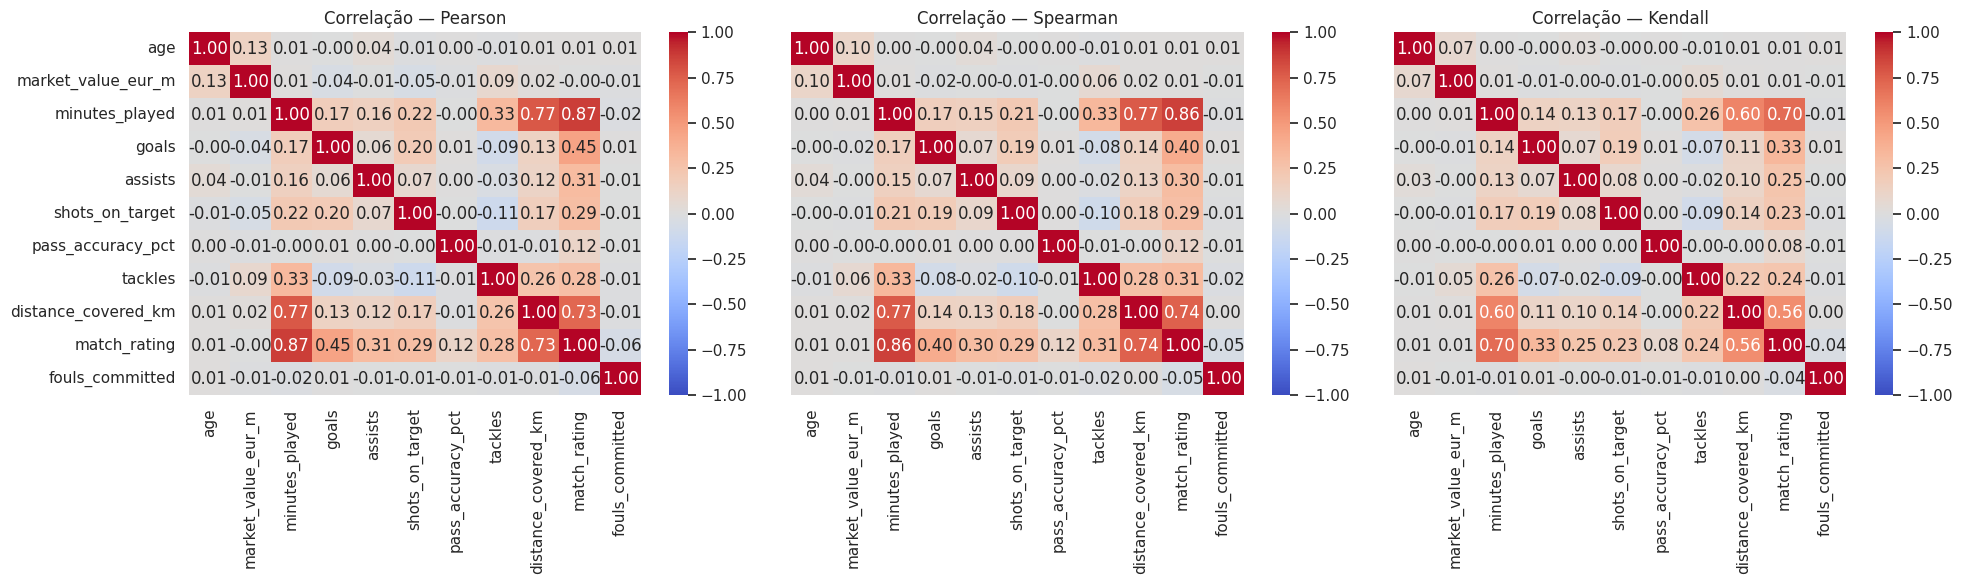

In [ ]:
corr_pearson = df[VARS_QUANT].corr(method="pearson")
corr_spearman = df[VARS_QUANT].corr(method="spearman")
corr_kendall = df[VARS_QUANT].corr(method="kendall")

fig, ax = plt.subplots(1, 3, figsize=(20, 6), sharey=True)

sns.heatmap(
    corr_pearson,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    ax=ax[0]
)
ax[0].set_title("Correlação — Pearson")

sns.heatmap(
    corr_spearman,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    ax=ax[1]
)
ax[1].set_title("Correlação — Spearman")

sns.heatmap(
    corr_kendall,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    ax=ax[2]
)
ax[2].set_title("Correlação — Kendall")

plt.tight_layout()
plt.show()


Como os dados do triângulo superior e inferior são simétricos, poderíamos plotar a matriz de correlação da seguinte forma.

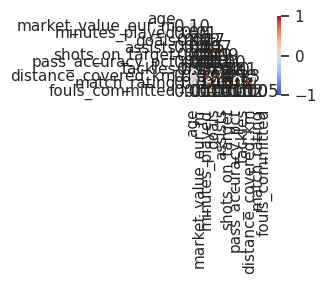

In [ ]:
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

plt.figure(figsize=(4, 3))
sns.heatmap(corr_spearman, mask=mask, annot=True, cmap="coolwarm", fmt=".2f", square=True, vmin=-1, vmax=1,)
plt.grid(False)

plt.tight_layout()
plt.show()

**Pra discutir:** Pearson e Spearman divergem bastante em algum par de variáveis? Se sim, isso é um sinal de relação não-linear (monotônica, mas não em linha reta) em que Spearman capturaria e Pearson não.

**RESPOSTA**

As correlações mais fortes aparecem principalmente entre minutes_played, distance_covered_km e match_rating. Pelo coeficiente de Spearman, minutes_played e match_rating apresentam correlação de aproximadamente 0,86, enquanto minutes_played e distance_covered_km apresentam cerca de 0,77. distance_covered_km e match_rating também possuem associação positiva forte, em torno de 0,74. Isso indica que, no dataset analisado, observações com maior tempo jogado tendem a apresentar maior distância percorrida e maiores notas de partida. Como as variáveis não apresentaram normalidade, o coeficiente de Spearman foi considerado o mais adequado para interpretação.

#### Dispersão (scatter) entre duas variáveis quantitativas

Escolhemos `age` x `thalach` por um motivo de domínio, não só estatístico: existe uma relação fisiológica entre idade e frequência cardíaca máxima, o que torna esse par um bom candidato pra visualizar uma tendência real.

**Nota para quando vocês replicarem no dataset de vocês:** nem sempre vai existir uma relação de domínio óbvia e, nesse caso, uma alternativa é escolher o par com o maior |correlação| na tabela acima, deixando a própria estatística guiar a escolha.

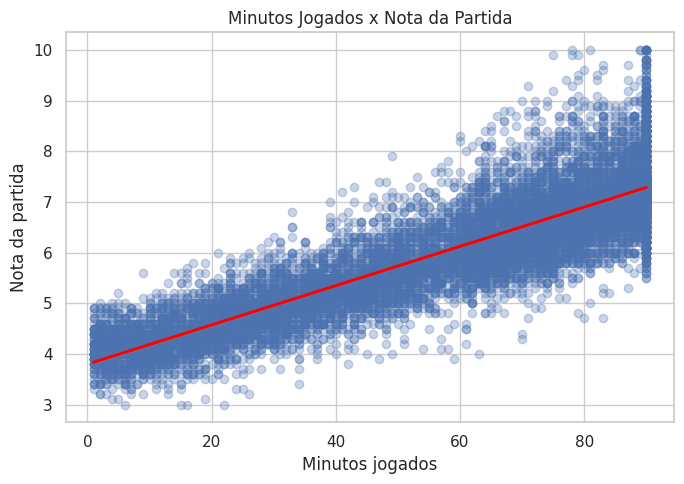

In [ ]:
plt.figure(figsize=(7, 5))

sns.regplot(
    data=df,
    x="minutes_played",
    y="match_rating",
    scatter_kws={"alpha": 0.3},
    line_kws={"color": "red"}
)

plt.title("Minutos Jogados x Nota da Partida")
plt.xlabel("Minutos jogados")
plt.ylabel("Nota da partida")

plt.tight_layout()
plt.show()

**Pra discutir:** existe uma tendência visível (conforme a idade aumenta, `thalach` tende a cair)? As duas classes ocupam regiões diferentes do gráfico, ou estão misturadas?

**RESPOSTA**

O gráfico de dispersão consegue mostrar uma relação bastante evidente só de olhar para ele. Quanto mais minutos jogados a nota da partida tende a aumentar conforme a linha de regressão. em 20 minutos jogados, os jogadores não passam da nota 6

#### Quantitativa x Qualitativa: Comparando Grupos

Na aula passada listamos **T-Test** (2 grupos) e **ANOVA** (3+ grupos) como testes paramétricos pra comparar uma variável quantitativa entre categorias, mas os dois assumem normalidade dentro de cada grupo.

Já vimos na Seção 3 (tabela generalizada do Shapiro-Wilk) que **nenhuma** das nossas quantitativas passou nesse teste. Isso significa que, tecnicamente, deveríamos usar os equivalentes **não-paramétricos**: **Mann-Whitney U** no lugar do T-Test, e **Kruskal-Wallis** no lugar da ANOVA. Vamos calcular os dois lado a lado pra comparar, mas o resultado não-paramétrico é o que deveríamos reportar como principal.

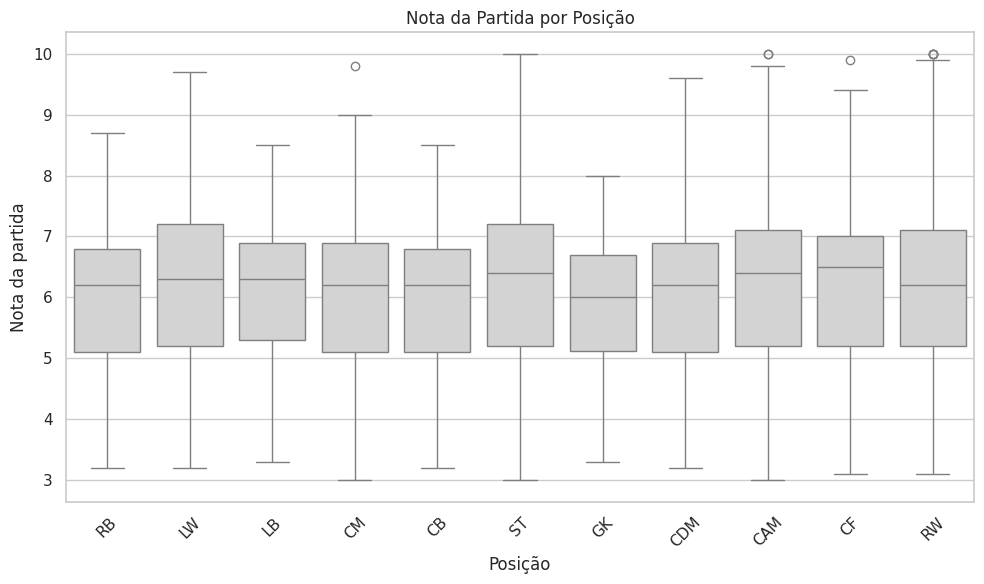

In [ ]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="position",
    y="match_rating",
    color=COR_NEUTRA
)

plt.title("Nota da Partida por Posição")
plt.xlabel("Posição")
plt.ylabel("Nota da partida")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
stat_anova, p_anova = stats.f_oneway(*grupos_posicao)

print(
    f"ANOVA          — match_rating entre posições: "
    f"estatística={stat_anova:.3f}, p-valor={p_anova:.5g}"
)

print(
    f"Kruskal-Wallis — match_rating entre posições: "
    f"estatística={stat_kw:.3f}, p-valor={p_kw:.5g}"
)

ANOVA          — match_rating entre posições: estatística=14.174, p-valor=2.5828e-25
Kruskal-Wallis — match_rating entre posições: estatística=120.292, p-valor=4.4149e-21


**Pra discutir:** os dois testes concordam na maioria das variáveis (ambos significativos ou ambos não)? Quando divergem, é o **Mann-Whitney** que deveríamos priorizar, é o que respeita a premissa que de fato temos (dados não-normais), não a que gostaríamos de ter.

**Nota:** mantivemos o T-Test aqui só como contraste pedagógico. Reportar apenas o T-Test, sem essa ressalva, seria estatisticamente inconsistente com o que a própria Seção 3 já mostrou sobre a normalidade dessas variáveis.

*Exemplo com 3+ grupos — ANOVA x Kruskal-Wallis*

`cp` (tipo de dor no peito) tem 4 categorias. Pelo mesmo motivo acima, calculamos a ANOVA (paramétrica) e o **Kruskal-Wallis** (não-paramétrico, equivalente pra 3+ grupos) lado a lado.

**RESPOSTAS**

O teste de Kruskal apresentou p-valor muito inferior a 0,05. Portanto, rejeitei a hipótese de que as distribuições de match_rating sejam iguais entre todas as posições. Isso indica que existe diferença estatisticamente significativa nas notas de partida entre pelo menos algumas posições. O boxplot também mostra pequenas diferenças entre as medianas e distribuições das posições. Como os dados não seguem normalidade, o resultado do Kruskal é o mais adequado para interpretação.

**Pra discutir:** o Kruskal-Wallis concorda com a ANOVA sobre existir diferença entre pelo menos uma categoria de `cp`? Como já sabemos que `thalach` não é normal, o **Kruskal-Wallis** é o resultado que deveríamos reportar como principal, a ANOVA fica só como contraste.

#### Quantitativa x Qualitativa

In [ ]:
# 1. Criar a tabela de contingência
contingencia_cartao = pd.crosstab(
    df["position"],
    df["yellow_card"]
)

contingencia_cartao

yellow_card,False,True
position,,
CAM,1328,137
CB,1260,124
CDM,895,91
CF,220,14
CM,1772,173
GK,734,76
LB,429,40
LW,1306,119
RB,744,70


In [ ]:
# 2. Fazer o teste Qui-Quadrado
chi2, p_chi2, gl, esperado = stats.chi2_contingency(
    contingencia_cartao
)

print(f"Qui-Quadrado: estatística={chi2:.3f}")
print(f"p-valor={p_chi2:.5g}")
print(f"graus de liberdade={gl}")

Qui-Quadrado: estatística=6.282
p-valor=0.79106
graus de liberdade=10


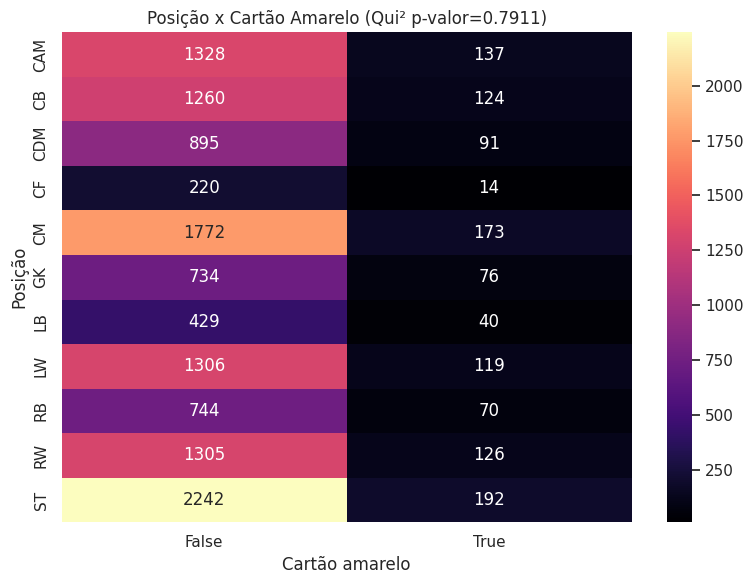

In [ ]:
# 3. Visualizar a tabela
plt.figure(figsize=(8, 6))

sns.heatmap(
    contingencia_cartao,
    annot=True,
    fmt="d",
    cmap="magma"
)

plt.title(f"Posição x Cartão Amarelo (Qui² p-valor={p_chi2:.4g})")
plt.xlabel("Cartão amarelo")
plt.ylabel("Posição")

plt.tight_layout()
plt.show()

**Pra discutir:** o p-valor do Qui-Quadrado indica que `thal` e `doenca_cardiaca` são independentes, ou há associação estatisticamente significativa entre elas?

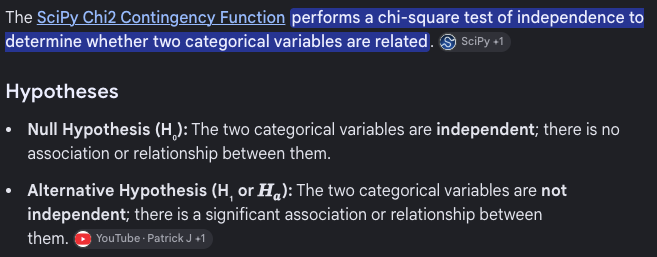

**RESPOSTA**

O teste Qui-Quadrado apresentou p-valor de aproximadamente 0,791, valor superior a 0,05. Portanto, não há evidência estatística suficiente para afirmar que existe associação entre a posição do jogador e a ocorrência de cartão amarelo no dataset analisado. Apesar de o heatmap mostrar diferenças nas quantidades absolutas entre posições, essas diferenças podem ser explicadas pela própria frequência de cada posição na base.

#### Avaliação de Fairness

Olhar o desbalanceamento da base inteira é só metade da história. Uma pergunta recorrente em discussões de **fairness** (justiça algorítmica) é: será que a distribuição do desfecho se comporta igual em diferentes subgrupos de atributos sensíveis (sexo e faixa etária, no nosso caso)? Se não, isso pode refletir um padrão real (ex: idade avançada é fator de risco documentado) ou um viés na forma como os dados foram coletados — de qualquer forma, é algo que vale mapear **antes** de qualquer modelagem.

In [ ]:
df["faixa_etaria"] = pd.cut(
    df["age"],
    bins=[0, 23, 28, 34, 100],
    labels=["Até 23", "24-28", "29-34", "35+"]
)

print("Desbalanceamento — faixa etária:")
print(metrica_desbalanceamento(df["faixa_etaria"]))

Desbalanceamento — faixa etária:
n_classes                 4.000
razao_desbalanceamento    1.350
entropia_normalizada      0.995
dtype: float64


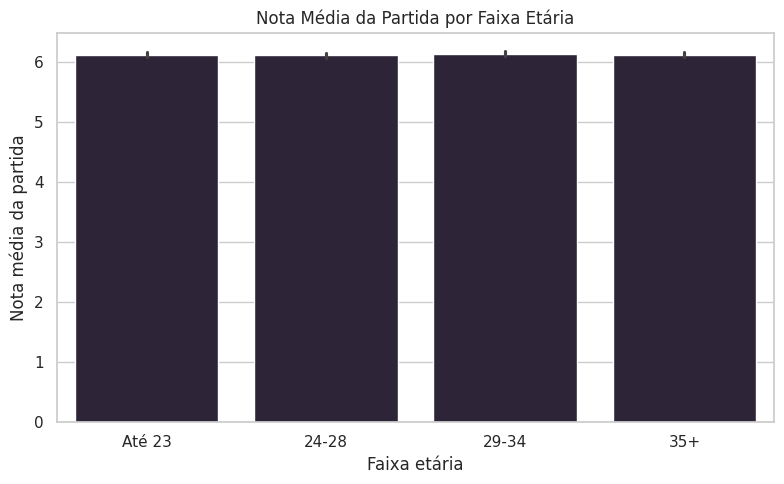

In [ ]:
media_rating_faixa = (
    df.groupby("faixa_etaria", observed=False)["match_rating"]
    .mean()
    .round(2)
)

media_rating_faixa

plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="faixa_etaria",
    y="match_rating",
    color=COR_DESTAQUE
)

plt.title("Nota Média da Partida por Faixa Etária")
plt.xlabel("Faixa etária")
plt.ylabel("Nota média da partida")

plt.tight_layout()
plt.show()

Pra discutir: a nota média da partida varia entre as faixas etárias? Essas diferenças podem refletir um padrão real do desempenho ou características do próprio dataset?


como podemos ver, a nota media da partida é muito semelhante entre todas as faixas etárias analisadas. Como falei no começo da atividade, nao posso dizer com certeza se isso é um dado real devido a confiabilidade do dataset.

In [ ]:
df["rating_categoria"] = pd.cut(
    df["match_rating"],
    bins=[0, 5, 7, 10],
    labels=["Baixa", "Média", "Alta"],
    include_lowest=True
)

In [ ]:
contingencia_fairness = pd.crosstab(
    df["faixa_etaria"],
    df["rating_categoria"]
)

contingencia_fairness

rating_categoria,Baixa,Média,Alta
faixa_etaria,,,
Até 23,884,1976,897
24-28,747,1711,743
29-34,795,2014,853
35+,640,1499,638


In [ ]:
chi2_f, p_f, gl_f, esperado_f = stats.chi2_contingency(
    contingencia_fairness
)

print(f"Qui-Quadrado: estatística={chi2_f:.3f}")
print(f"p-valor={p_f:.5g}")
print(f"graus de liberdade={gl_f}")

Qui-Quadrado: estatística=5.922
p-valor=0.43197
graus de liberdade=6


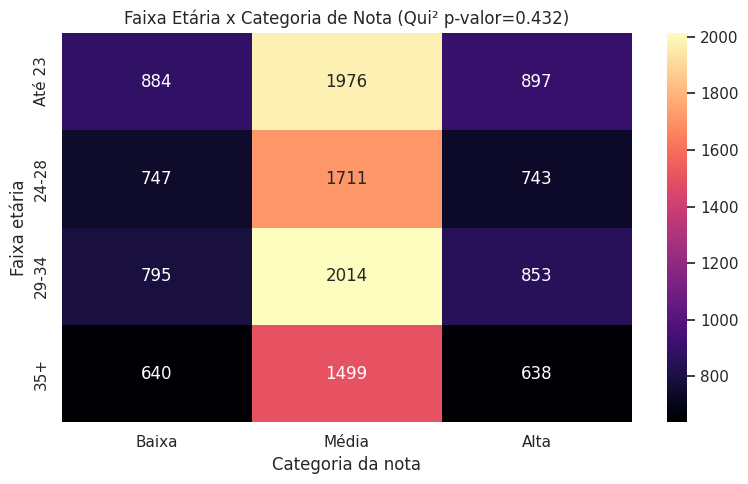

In [ ]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    contingencia_fairness,
    annot=True,
    fmt="d",
    cmap="magma"
)

plt.title(
    f"Faixa Etária x Categoria de Nota "
    f"(Qui² p-valor={p_f:.4g})"
)

plt.xlabel("Categoria da nota")
plt.ylabel("Faixa etária")

plt.tight_layout()
plt.show()

**Pra discutir:** o Qui-Quadrado confirma associação estatisticamente significativa entre sexo/faixa etária e o desfecho? Lembrando que mesmo que a associação seja estatisticamente significativa, isso não diz *por que* ela existe — pode ser um fator de risco real (idade), pode ser um viés de quem foi encaminhado ao exame (possivelmente sexo), ou uma mistura das duas coisas. Um teste estatístico aponta *que* existe associação, não *a causa* dela — essa distinção é o núcleo de qualquer discussão séria de fairness.

Essa análise não prova que o dataset seja “justo” de forma geral. Ela apenas mostra que, para o recorte analisado, não foi identificada uma associação estatisticamente significativa entre faixa etária e categoria de nota. Outras variáveis e grupos poderiam apresentar comportamentos diferentes.

#### Outliers bivariados

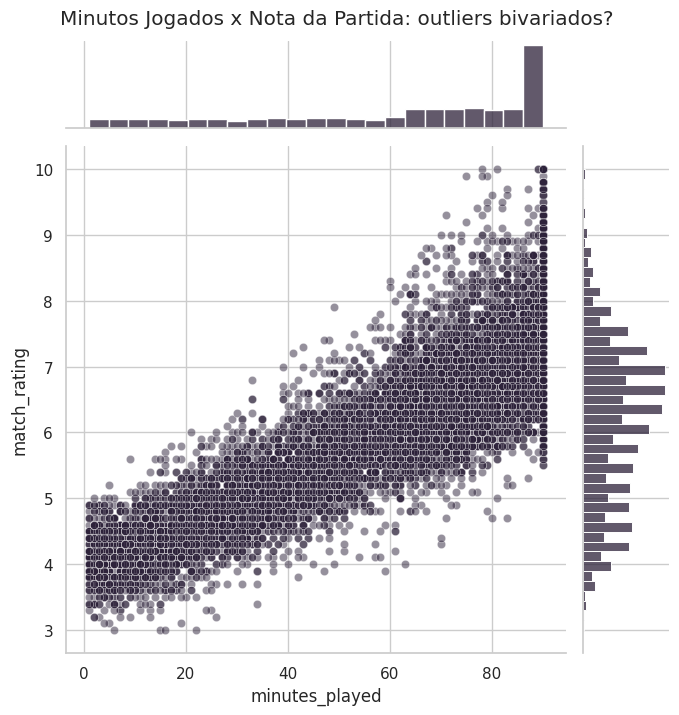

In [ ]:
sns.jointplot(
    data=df,
    x="minutes_played",
    y="match_rating",
    kind="scatter",
    color=COR_DESTAQUE,
    alpha=0.5,
    height=7
)

plt.suptitle(
    "Minutos Jogados x Nota da Partida: outliers bivariados?",
    y=1.02
)

plt.show()

**Pra discutir:** existe algum ponto que não parecia outlier nos histogramas univariados (Seção 3/4), mas que se destaca aqui como uma combinação incomum de `trestbps` e `chol`?

 Esse gráfico representa bem o que gostaria de passar. Um outlier bivariado aqui seria um jogador jogar 7 minutos e ter nota 10. aqui isso parece não acontecer.

#### Análise Multivariada

##### Matriz de Correlação

In [ ]:
VARS_CORRELOGRAMA = [
    "minutes_played",
    "goals",
    "assists",
    "shots_on_target",
    "distance_covered_km",
    "match_rating"
]

In [ ]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

def circulo_correlacao(x, y, **kwargs):
    r = x.corr(y, method="spearman")

    ax = plt.gca()

    ax.scatter(
        [0.5],
        [0.5],
        s=abs(r) * 4000,
        c=[r],
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        transform=ax.transAxes,
        edgecolor="white",
        linewidth=0.5
    )

    ax.annotate(
        f"{r:.2f}",
        xy=(0.5, 0.5),
        xycoords=ax.transAxes,
        ha="center",
        va="center",
        fontsize=10,
        color="white" if abs(r) > 0.5 else "black"
    )

    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)

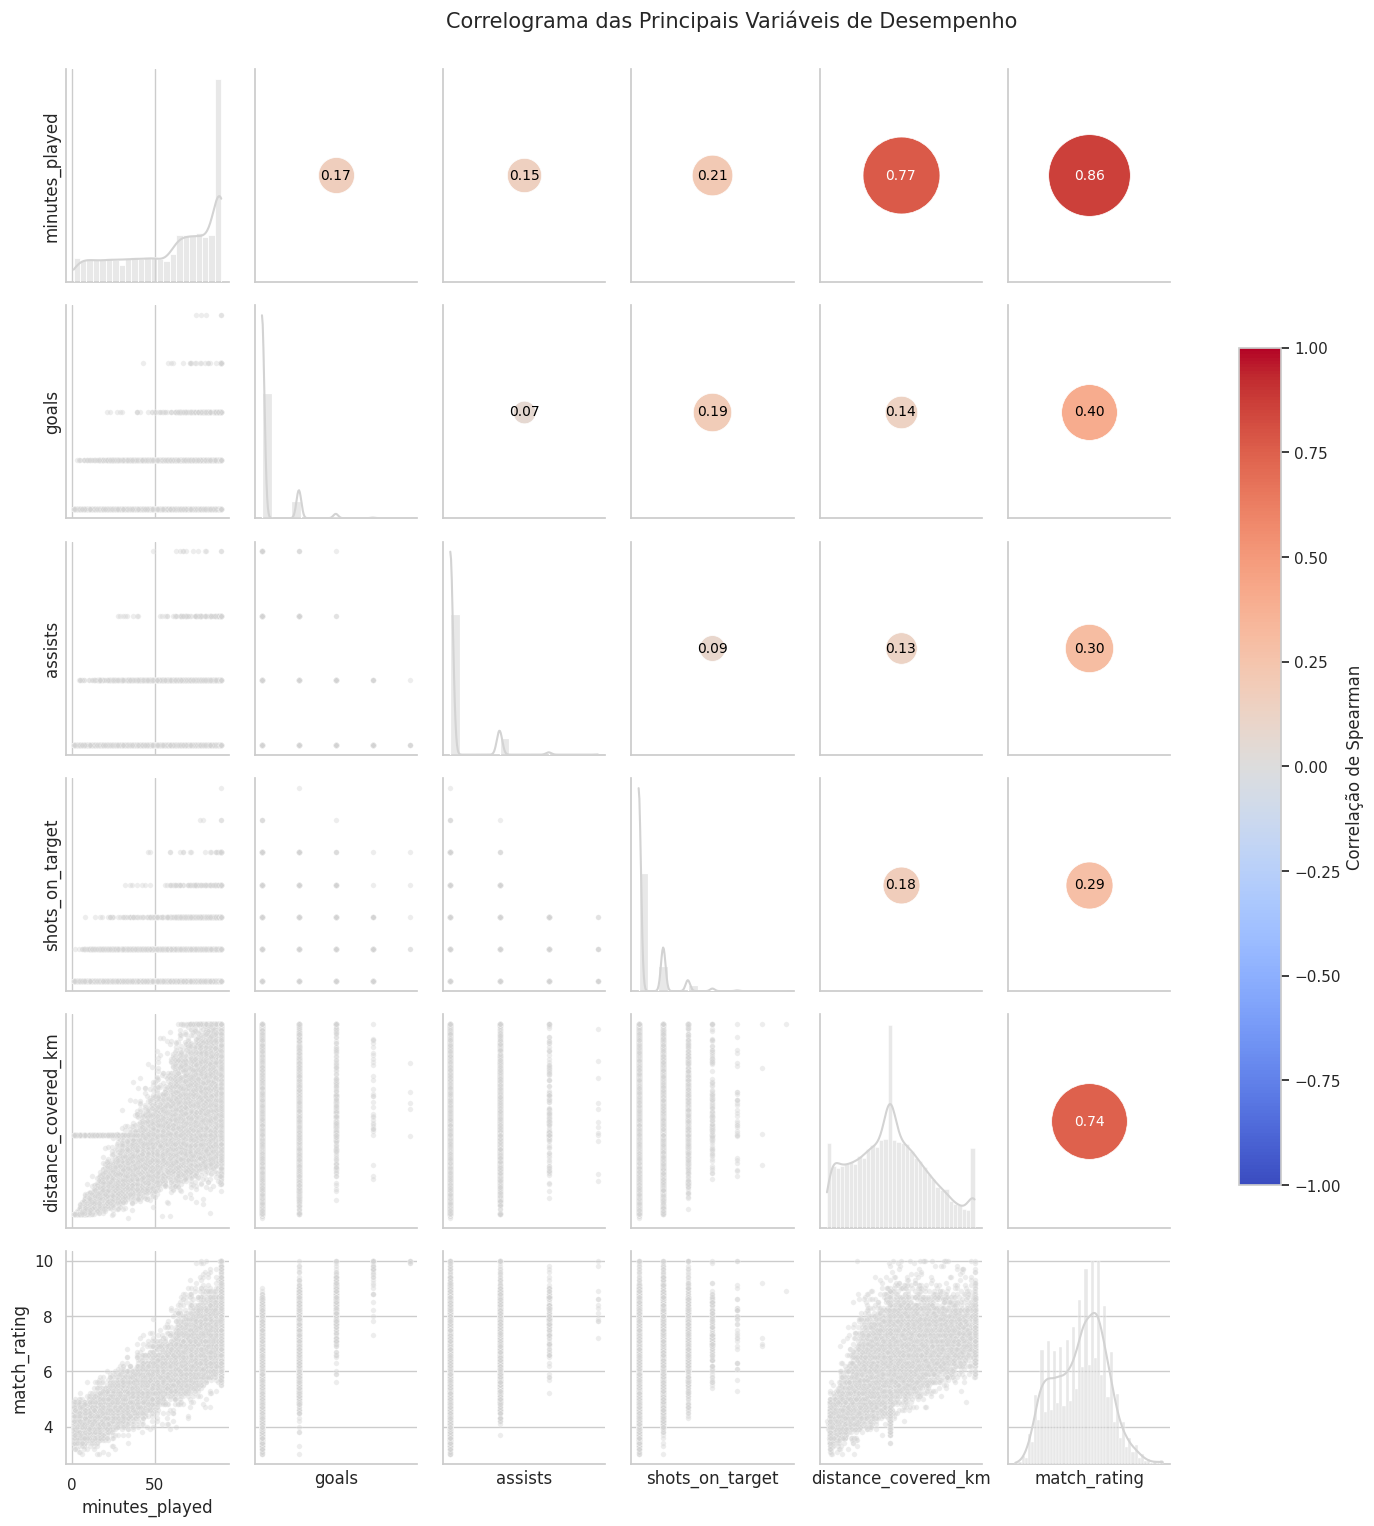

In [ ]:
g = sns.PairGrid(
    df[VARS_CORRELOGRAMA],
    diag_sharey=False
)

g.map_lower(
    sns.scatterplot,
    color=COR_NEUTRA,
    alpha=0.4,
    s=15
)

g.map_diag(
    sns.histplot,
    color=COR_NEUTRA,
    kde=True
)

g.map_upper(
    circulo_correlacao
)

sm = ScalarMappable(
    norm=Normalize(-1, 1),
    cmap="coolwarm"
)

sm.set_array([])

g.fig.colorbar(
    sm,
    ax=g.axes,
    shrink=0.6,
    label="Correlação de Spearman"
)

g.fig.suptitle(
    "Correlograma das Principais Variáveis de Desempenho",
    y=1.02,
    fontsize=15
)

plt.show()

**Como interpretar:**


*   |r| < 0.3 ~ fraca,
*   0.3 < |r| < 0.7 ~ moderada,
*  |r| > 0.7 ~ forte.

Alguma correlação chama atenção por ser forte o suficiente pra sugerir redundância entre variáveis?

##### Correlograma

O correlograma reforça os padrões observados anteriormente na matriz de correlação. As relações mais fortes aparecem principalmente entre minutes_played, distance_covered_km e match_rating. Podemos ver na parte de match_rating algo que eu citei algumas vezes durante a atividade

## Hands-on!

Agora é a vez de você realizar uma EDA com os seu conjunto de dados recebidos.

Para isso crie um novo notebook e vamos fazer **em sala** uma EDA seguindo a aula prática que acabamos de ter. Os tópicos desenvolvidos são referências.

Para esse exercício é de suma importância que vocês **elaborem perguntas** e **discutam** os resultados obtidos. Por exemplo, se houver dados faltantes, busque *entender* o porquê e *justifique* sua decisão.

Após o desenvolvimento da EDA em si, é necessário fazer uma síntese considerando:


1.   Principais conclusões em 3 a 5 pontos
2.   Declaração de Uso de IA (Ferramenta utilizada, Para o que foi aplicada e o que foi aceito/modificado/rejeitado e por quê)

O **entregável** será um notebook `ipynb`que trará todo o código, discussão, principais conclusões e declaração de uso de IA.




## Principais conclusões

1

O dataset tem uns 13 mil registros e 21 atributos, com informações de desempenho de jogadores. Foram encontrados valores ausentes em market_value_eur_m, pass_accuracy_pct e distance_covered_km, posteriormente tratados por imputação pela mediana.


2

Algumas variáveis apresentaram forte assimetria e presença de valores extremos, principalmente market_value_eur_m, goals, assists e shots_on_target. Os outliers foram mantidos, pois valores extremos podem ser plausíveis no contexto futebolístico e não havia informação suficiente para classificá-los como erros.


3

As relações mais fortes entre variáveis quantitativas ocorreram entre minutes_played, distance_covered_km e match_rating. A correlação de Spearman entre minutos jogados e nota da partida foi de aproximadamente 0,86, indicando associação positiva forte no dataset.


4

Foi encontrada diferença estatisticamente significativa de match_rating entre as posições dos jogadores pelo teste de Kruskal-Wallis. Por outro lado, não foi identificada associação estatisticamente significativa entre posição e ocorrência de cartão amarelo.


5

A análise de fairness por faixa etária não encontrou evidência estatisticamente significativa de associação entre idade agrupada e categoria de nota. Entretanto, foram observadas inconsistências entre alguns registros e informações conhecidas do futebol, indicando que os resultados devem ser interpretados como características do dataset e não como retrato fiel da realidade da FIFA 2026.

##  Declaração de Uso de IA

Utilizei o gpt 5.6 sol(médio) para me ajudar principalmente na criação dos códigos e entender alguns mecanismos de como funciona um gráfico, sempre passando por uma analise antes de 'jogar' aqui. Para ser mais específico utilizei na parte do heatmap e na parte do spearmen. Para além disso utilizei também nas últimas 2 etapas da conclusão.

## Limitações da Análise

Como falei no começo da atividade, o dataset apresenta algumas inconsistências em relação a informações dos jogadores. Lionel messi por exemplo aparece com 39 anos, o que não é verdade para a copa de 2026.